# Reproduction of the base paper locally (VS Code)
**Zhang et al., "Class-Conditioned Image Synthesis with Diffusion for Imbalanced Diabetic Retinopathy Grading", MICCAI 2025**
(official code: https://github.com/AlanZhang1995/ECC_DM_for_DR)

This notebook re-implements the full pipeline of the paper and its released code and produces Table 1:

| Section | What happens | Base-paper source |
|---|---|---|
| 1-3 | DDR data, the paper's split (official train / 47-per-class val / official test), preprocessing, statistics & samples | Sec. 4.1, `preprocess_images.py` |
| 4 | Official LANet checkpoints as the *semantic-quality scorer ensemble*; evaluation of the authors' LANet* | Sec. 3.2 |
| 5 | SD1.5 + DreamBooth prior preservation + LoRA (rank 8), **basic DM** and **ECC DM**, one model per stage (mild, severe) | Sec. 3.1, 3.3, `Fundus_train_text_to_image_lora3.py` |
| 6-7 | Candidate generation, semantic scoring, w/o filter vs w/ filter [0.7, 0.9], 2K images per class | Sec. 3.2, `Fundus_test.py`, `select_topK_sync.py` |
| 8-9 | LANet training for every Table-1 row, test evaluation, reproduced Table 1 vs paper | Sec. 4.2, `main_lanet.py` |
| 10-12 | (optional) Fig. 2a amount sweep, FID/KID of the synthetic data, export for notebook 2 | Fig. 2 |

**Every long step prints per-step/epoch training AND validation results, saves `best` and `last` checkpoints with the full
history, and resumes exactly where it stopped.** Read `README_base_paper.md` before the first run.

## 0. Setup (VS Code, local GPU)
Select the **`Python (sara_genai)`** kernel (top-right in VS Code). Datasets go in `PROJECT_ROOT/data` exactly as described in `README_local.md`.

In [1]:
# =============================================================================
# 0.1  Environment check (packages come from requirements.txt in the 'sara_genai' venv - nothing installs here)
# =============================================================================
import os; os.environ["HF_HUB_DISABLE_XET"] = "1"   # lab network: classic HF downloads (must run before any huggingface_hub import)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less GPU-memory fragmentation (before torch import)
import sys, os, importlib
print("Python:", sys.version.split()[0], "| executable:", sys.executable)
for _m in ["torch", "torchvision", "diffusers", "transformers", "peft", "timm", "sklearn", "pyod", "torchmetrics"]:
    try:
        _v = importlib.import_module(_m).__version__
        print(f"  {_m:12s} {_v}")
    except Exception as _e:
        print(f"  {_m:12s} MISSING -> pip install -r requirements.txt  ({type(_e).__name__})")
import torch
if torch.cuda.is_available():
    print("CUDA:", torch.version.cuda, "| GPU:", torch.cuda.get_device_name(0),
          f"| {torch.cuda.get_device_properties(0).total_memory/1024**3:.1f} GB")
else:
    print("WARNING: CUDA not available - install the CUDA build of torch (see README) and select the 'sara_genai' kernel.")

# Hugging Face token: needed only for gated models (RETFound in notebook 2).
# Either run `hf auth login` once in the activated venv, or set the environment variable HF_TOKEN.
if os.environ.get("HF_TOKEN"):
    from huggingface_hub import login; login(token=os.environ["HF_TOKEN"]); print("Logged in to Hugging Face via HF_TOKEN")

Python: 3.12.16 | executable: /home/i269028/sara_genai/sara_genai/bin/python
  torch        2.7.1+cu126
  torchvision  0.22.1+cu126
  diffusers    0.42.1
  transformers 5.22.1
  peft         0.21.2
  timm         1.0.31
  sklearn      1.9.1
  pyod         3.6.8
  torchmetrics 1.9.0
CUDA: 12.6 | GPU: NVIDIA RTX 4000 Ada Generation | 19.6 GB


## 0.3 Core utilities (environment, time budget, checkpoint I/O)

In [2]:
# =============================================================================
# Core imports, environment detection, reproducibility, time budget, I/O helpers
# =============================================================================
import os, sys, json, time, math, random, shutil, glob, re, gc, warnings, subprocess, copy
from pathlib import Path
from collections import defaultdict, OrderedDict

import numpy as np
import pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True          # some fundus JPEGs are slightly truncated

import matplotlib
matplotlib.use("Agg")                            # headless-safe; figures are saved AND shown below
import matplotlib.pyplot as plt
try:
    from IPython.display import display, Image as IPyImage
except Exception:                                # running as a plain script
    display = print
    IPyImage = None

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

warnings.filterwarnings("ignore", category=UserWarning)

IS_KAGGLE = os.path.exists("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Where attached / downloaded datasets are searched for. Kaggle: /kaggle/input. Local (VS Code): set in the
# configuration cell to your data folder, e.g. INPUT_ROOTS = [r"D:\sara_genai\data"].
INPUT_ROOTS = ["/kaggle/input"] if IS_KAGGLE else []
print(f"Running on Kaggle: {IS_KAGGLE} | device: {DEVICE}")
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {p.name}  {p.total_memory/1024**3:.1f} GB")


def seed_everything(seed: int = 42, deterministic: bool = False):
    """Seed python, numpy and torch. deterministic=True mirrors the base repo
    (cudnn.deterministic=True, benchmark=False) but is slower."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic


class OutOfTime(Exception):
    """Raised by long loops when the session time budget is nearly used up.
    Everything needed to resume has already been saved when this is raised."""


class TimeBudget:
    """Kaggle GPU sessions stop after ~12 h. Every long loop calls
    BUDGET.check() and stops cleanly (after saving a checkpoint) before the limit,
    so that 'Save Version' can persist /kaggle/working and you can resume."""
    def __init__(self, hours: float, reserve_minutes: float = 25):
        self.t0 = time.time()
        self.limit = hours * 3600.0
        self.reserve = reserve_minutes * 60.0

    def elapsed_h(self):
        return (time.time() - self.t0) / 3600.0

    def remaining_h(self):
        return max(0.0, (self.limit - (time.time() - self.t0)) / 3600.0)

    def nearly_out(self):
        return (time.time() - self.t0) > (self.limit - self.reserve)

    def check(self, where=""):
        if self.nearly_out():
            raise OutOfTime(f"Time budget reached at: {where}. Checkpoints are saved. "
                            f"Save a version of the notebook, then resume (see README).")


def save_json(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))
    os.replace(tmp, path)


def load_json(path, default=None):
    path = Path(path)
    if not path.exists():
        return default
    with open(path) as f:
        return json.load(f)


def atomic_torch_save(obj, path):
    """Write to a temp file then rename, so an interrupted save never corrupts the checkpoint."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def get_rng_state():
    st = {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}
    if torch.cuda.is_available():
        st["cuda"] = torch.cuda.get_rng_state_all()
    return st


def set_rng_state(st):
    if st is None:
        return
    try:
        random.setstate(st["python"]); np.random.set_state(st["numpy"]); torch.set_rng_state(st["torch"])
        if torch.cuda.is_available() and "cuda" in st:
            torch.cuda.set_rng_state_all(st["cuda"])
    except Exception as e:
        print("[warn] could not restore RNG state:", e)


def restore_previous_outputs(src_dir, dst_dir):
    """Resume across Kaggle sessions: copy the output of a previous notebook version
    (attached via 'Add Input -> Your Work / Notebook Output') into /kaggle/working.
    Existing files in dst are kept (never overwritten)."""
    if not src_dir:
        return
    src_dir, dst_dir = Path(src_dir), Path(dst_dir)
    if not src_dir.exists():
        print(f"[resume] {src_dir} not found - starting fresh.")
        return
    n = 0
    for p in src_dir.rglob("*"):
        if p.is_file():
            q = dst_dir / p.relative_to(src_dir)
            if not q.exists():
                q.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(p, q); n += 1
    print(f"[resume] restored {n} files from {src_dir} -> {dst_dir}")


def show_saved_figure(path):
    """Display a saved PNG inline in Jupyter (no-op when running as a script)."""
    if IPyImage is not None and Path(path).exists():
        try:
            display(IPyImage(filename=str(path)))
        except Exception:
            pass


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def disk_usage_gb(path):
    total = 0
    for p in Path(path).rglob("*"):
        if p.is_file():
            total += p.stat().st_size
    return total / 1024**3

Running on Kaggle: False | device: cuda
  GPU 0: NVIDIA RTX 4000 Ada Generation  19.6 GB


## 0.4 Metrics and plotting helpers
The **same** metric code is used in both notebooks, so the final comparison table is like-for-like.

In [3]:
# =============================================================================
# Metrics (identical in both notebooks so the comparison table is like-for-like)
# =============================================================================
from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score, confusion_matrix,
                             matthews_corrcoef, roc_auc_score, precision_score, recall_score)

GRADE_NAMES = ["No DR", "Mild", "Moderate", "Severe", "PDR"]
STAGE_WORDS = {0: "normal", 1: "mild DR", 2: "moderate DR", 3: "severe DR", 4: "proliferative DR"}   # base-paper prompt words


def expected_calibration_error(probs, y_true, n_bins=15):
    """Top-label ECE on the 5-grade softmax."""
    probs = np.asarray(probs); y_true = np.asarray(y_true)
    conf = probs.max(1); pred = probs.argmax(1); correct = (pred == y_true).astype(float)
    bins = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def compute_metrics(y_true, y_pred, probs_grade=None, probs_referable=None, num_classes=5):
    """All values are fractions in [0,1] (multiply by 100 for tables).
    balanced_acc == the base paper's 'B. Acc' (mean per-class recall, i.e. normed_acc in main_lanet.py)
    kappa        == quadratic weighted kappa (the base paper's 'Kappa')
    acc          == plain accuracy (the base paper's 'Acc')."""
    y_true = np.asarray(y_true).astype(int); y_pred = np.asarray(y_pred).astype(int)
    labels = list(range(num_classes))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    with np.errstate(divide="ignore", invalid="ignore"):
        per_recall = np.where(cm.sum(1) > 0, np.diag(cm) / cm.sum(1), np.nan)
        per_prec = np.where(cm.sum(0) > 0, np.diag(cm) / cm.sum(0), np.nan)
    out = {
        "balanced_acc": float(np.nanmean(per_recall)),
        "kappa": float(cohen_kappa_score(y_true, y_pred, weights="quadratic")),
        "acc": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "per_class_recall": [float(x) for x in per_recall],
        "per_class_precision": [float(x) for x in per_prec],
        "confusion_matrix": cm.tolist(),
        "n": int(len(y_true)),
    }
    if probs_grade is not None:
        out["ece"] = expected_calibration_error(probs_grade, y_true)
    if probs_referable is not None:
        # 'any DR' head of LANet (label_clf = 0 if grade 0 else 1)
        yb = (y_true > 0).astype(int)
        try:
            out["auroc_anyDR"] = float(roc_auc_score(yb, np.asarray(probs_referable)))
        except ValueError:
            out["auroc_anyDR"] = float("nan")
    return out


def fmt_metrics(m, keys=("balanced_acc", "kappa", "acc", "macro_f1")):
    return " | ".join(f"{k}={100*m[k]:.2f}" for k in keys if k in m)


def paired_bootstrap(y_true, pred_a, pred_b, metric="balanced_acc", n_boot=1000, seed=0):
    """Paired bootstrap over test images: CI of (metric_b - metric_a) and a two-sided p-value."""
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    n = len(y_true); diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        ma = compute_metrics(y_true[idx], pred_a[idx])[metric]
        mb = compute_metrics(y_true[idx], pred_b[idx])[metric]
        diffs.append(mb - ma)
    diffs = np.array(diffs)
    p = 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
    return {"mean_diff": float(diffs.mean()), "ci95": [float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))],
            "p_value": float(min(1.0, p)), "n_boot": n_boot, "metric": metric}


# =============================================================================
# Plot helpers (all figures saved at 300 dpi for the paper)
# =============================================================================
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})


def save_fig(fig, path, show=True):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print("saved figure ->", path)
    if show:
        show_saved_figure(path)


def plot_confusion(cm, title, path, normalize=True):
    cm = np.asarray(cm, dtype=float)
    disp = cm / np.clip(cm.sum(1, keepdims=True), 1, None) if normalize else cm
    fig, ax = plt.subplots(figsize=(4.6, 4.0))
    im = ax.imshow(disp, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xticklabels(GRADE_NAMES, rotation=35, ha="right"); ax.set_yticklabels(GRADE_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title); ax.grid(False)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{disp[i, j]:.2f}" if normalize else int(cm[i, j]), ha="center", va="center",
                    color="white" if disp[i, j] > 0.5 * disp.max() else "black", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046)
    save_fig(fig, path)


def plot_classifier_history(hist, title, path):
    """hist: list of per-epoch dicts written by train_classifier()."""
    if not hist:
        print("no history to plot"); return
    df = pd.DataFrame(hist)
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    axes[0].plot(df.epoch, df.train_loss, label="train total loss")
    if "train_loss_grade" in df: axes[0].plot(df.epoch, df.train_loss_grade, label="train grade CE")
    if "val_loss" in df: axes[0].plot(df.epoch, df.val_loss, label="val grade CE")
    axes[0].set_title("Loss"); axes[0].legend()
    axes[1].plot(df.epoch, 100 * df.train_acc, label="train acc")
    axes[1].plot(df.epoch, 100 * df.val_acc, label="val acc")
    axes[1].plot(df.epoch, 100 * df.val_balanced_acc, label="val balanced acc")
    axes[1].set_title("Accuracy (%)"); axes[1].legend()
    axes[2].plot(df.epoch, 100 * df.val_kappa, label="val QWK", color="C3")
    axes[2].plot(df.epoch, 100 * df.val_macro_f1, label="val macro-F1", color="C4")
    axes[2].set_title("Val QWK / macro-F1 (%)"); axes[2].legend()
    axes[3].plot(df.epoch, df.lr, color="C5"); axes[3].set_title("Learning rate"); axes[3].set_yscale("log")
    for a in axes: a.set_xlabel("epoch")
    fig.suptitle(title, y=1.04)
    save_fig(fig, path)


def plot_diffusion_history(hist, title, path):
    if not hist:
        print("no history to plot"); return
    df = pd.DataFrame(hist)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    axes[0].plot(df.step, df.loss_instance, label="instance (DDR) MSE", alpha=.8)
    axes[0].plot(df.step, df.loss_prior, label="prior MSE", alpha=.8)
    if "loss_sync" in df and df.loss_sync.abs().sum() > 0:
        axes[0].plot(df.step, df.loss_sync, label="ECC (sync) MSE", alpha=.8)
    axes[0].set_title("Diffusion training losses"); axes[0].legend(); axes[0].set_xlabel("optimizer step")
    axes[1].plot(df.step, df.loss_total, color="k"); axes[1].set_title("Total loss"); axes[1].set_xlabel("optimizer step")
    if "val_semantic_score" in df and df.val_semantic_score.notna().any():
        d = df[df.val_semantic_score.notna()]
        axes[2].plot(d.step, d.val_semantic_score, "o-", color="C3")
        axes[2].set_title("Validation: mean semantic score of samples"); axes[2].set_xlabel("optimizer step")
    else:
        axes[2].set_visible(False)
    fig.suptitle(title, y=1.04)
    save_fig(fig, path)


def image_grid(images, nrow, titles=None, path=None, figsize_per=2.0, suptitle=None):
    n = len(images); ncol = int(math.ceil(n / nrow))
    fig, axes = plt.subplots(nrow, ncol, figsize=(figsize_per * ncol, figsize_per * nrow))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            img = images[i]
            if isinstance(img, (str, Path)):
                img = Image.open(img).convert("RGB")
            ax.imshow(img)
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    if suptitle: fig.suptitle(suptitle)
    if path is not None:
        save_fig(fig, path)
    else:
        plt.close(fig)

## 0.5 Data utilities: locate/download DDR, APTOS, EyePACS; base-repo preprocessing; splits; statistics

In [4]:
# =============================================================================
# Data: locate / download DDR, APTOS, EyePACS; preprocess (base-repo method); splits
# =============================================================================
from concurrent.futures import ThreadPoolExecutor   # threads: picklable-free, PIL/cv2 release the GIL
import cv2

IMG_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}


def find_dirs_containing(roots, required_files, max_depth=6):
    """Return every directory (under any root) that contains ALL `required_files`."""
    hits = []
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        base_depth = len(root.parts)
        for dirpath, dirnames, filenames in os.walk(root):
            if len(Path(dirpath).parts) - base_depth > max_depth:
                dirnames[:] = []
                continue
            if all(f in filenames for f in required_files):
                hits.append(Path(dirpath))
    return hits


def index_images(root):
    """Map image basename -> full path for every image file below `root`."""
    idx = {}
    for dirpath, _, filenames in os.walk(root):
        for fn in filenames:
            if Path(fn).suffix.lower() in IMG_EXTS:
                idx.setdefault(fn, os.path.join(dirpath, fn))
    return idx


def read_ddr_txt(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 2:
                rows.append((parts[0], int(parts[1])))
    return pd.DataFrame(rows, columns=["name", "label"])


def locate_or_download_ddr(cfg):
    """1) look for an attached Kaggle dataset that contains DR_grading train/valid/test.txt;
       2) otherwise download the DR_grading folder of the public Hugging Face mirror."""
    search_roots = list(INPUT_ROOTS) + [cfg["RAW_DIR"]]
    hits = find_dirs_containing(search_roots, ["train.txt", "valid.txt", "test.txt"])
    if hits:
        print("Found DDR DR_grading folder:", hits[0]); return hits[0]
    if not cfg.get("DDR_DOWNLOAD_FROM_HF", True):
        raise FileNotFoundError("DDR not found. Attach it as a Kaggle dataset or set DDR_DOWNLOAD_FROM_HF=True (see README).")
    from huggingface_hub import snapshot_download
    print(f"Downloading DR_grading from HF dataset '{cfg['DDR_HF_REPO']}' (~several GB, one-time) ...")
    snapshot_download(repo_id=cfg["DDR_HF_REPO"], repo_type="dataset",
                      allow_patterns=["DR_grading/*", "DR_grading/**"],
                      local_dir=str(Path(cfg["RAW_DIR"]) / "DDR"), max_workers=8)
    hits = find_dirs_containing([Path(cfg["RAW_DIR"]) / "DDR"], ["train.txt", "valid.txt", "test.txt"])
    if not hits:
        raise FileNotFoundError("Download finished but train/valid/test.txt were not found - check the HF repo layout.")
    return hits[0]


def locate_aptos():
    hits = find_dirs_containing(INPUT_ROOTS, ["train.csv", "test.csv"])
    for h in hits:
        if (h / "train_images").exists():
            print("Found APTOS 2019:", h); return h
    print("[info] APTOS 2019 not found under", INPUT_ROOTS, "(only used for the prior-preservation pool).")
    return None


def locate_eyepacs():
    for name in ["trainLabels.csv", "trainLabels_cropped.csv"]:
        hits = find_dirs_containing(INPUT_ROOTS, [name])
        if hits:
            print("Found EyePACS labels:", hits[0] / name); return hits[0], name
    print("[info] EyePACS not attached (optional; only used for the prior-preservation pool).")
    return None, None


# ---------- preprocessing: identical logic to data_structure/DR_grading/preprocess_images.py ----------
def trim_fundus(im):
    """Remove black borders (base repo `trim`). Keeps the original's cv2.COLOR_BGR2GRAY call on an RGB array."""
    percentage = 0.02
    img = np.array(im)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    nz = img_gray[img_gray != 0]
    if nz.size == 0:
        return im
    mask = img_gray > 0.1 * np.mean(nz)
    rows = np.where(mask.sum(1) > img.shape[1] * percentage)[0]
    cols = np.where(mask.sum(0) > img.shape[0] * percentage)[0]
    if len(rows) == 0 or len(cols) == 0:
        return im
    return Image.fromarray(img[rows.min(): rows.max() + 1, cols.min(): cols.max() + 1])


def resize_maintain_aspect(image, desired_size):
    old = image.size
    ratio = float(desired_size) / max(old)
    new = tuple(max(1, int(x * ratio)) for x in old)
    im = image.resize(new, Image.LANCZOS)                       # Image.ANTIALIAS was removed in Pillow 10
    out = Image.new("RGB", (desired_size, desired_size))
    out.paste(im, ((desired_size - new[0]) // 2, (desired_size - new[1]) // 2))
    return out


def _preprocess_one(args):
    src, dst, size = args
    if os.path.exists(dst):
        return dst, True
    try:
        im = Image.open(src).convert("RGB")
        im = resize_maintain_aspect(trim_fundus(im), size)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        im.save(dst, quality=95)
        return dst, True
    except Exception as e:
        print("  [skip]", src, e)
        return dst, False


def preprocess_many(src_paths, out_dir, size, workers=None):
    """Preprocess (trim + square-pad + resize) and save as JPEG q95. Resumable: existing outputs are skipped."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    jobs, mapping = [], {}
    for s in src_paths:
        dst = str(out_dir / (Path(s).stem + ".jpg"))
        mapping[s] = dst
        jobs.append((s, dst, size))
    todo = [j for j in jobs if not os.path.exists(j[1])]
    print(f"preprocess -> {out_dir}: {len(jobs)} images ({len(todo)} new)")
    if todo:
        from tqdm.auto import tqdm
        with ThreadPoolExecutor(max_workers=workers or (os.cpu_count() or 4) * 2) as ex:
            for _ in tqdm(ex.map(_preprocess_one, todo), total=len(todo)):
                pass
    ok = {s: d for s, d in mapping.items() if os.path.exists(d)}
    return ok


def build_ddr_tables(cfg, ddr_root):
    """Read official DR_grading txt files, preprocess every referenced image once, return dataframes."""
    img_index = index_images(ddr_root)
    tables = {}
    for split in ["train", "valid", "test"]:
        df = read_ddr_txt(Path(ddr_root) / f"{split}.txt")
        df["src"] = df["name"].map(img_index)
        missing = df["src"].isna().sum()
        if missing:
            print(f"  [warn] {missing} images listed in {split}.txt not found on disk - dropped")
        tables[split] = df.dropna(subset=["src"]).reset_index(drop=True)
    all_src = pd.concat(tables.values())["src"].unique().tolist()
    mapping = preprocess_many(all_src, Path(cfg["DATA_DIR"]) / "ddr_preprocessed", cfg["PREPROC_SIZE"])
    for split, df in tables.items():
        df["path"] = df["src"].map(mapping)
        tables[split] = df.dropna(subset=["path"]).reset_index(drop=True)[["name", "label", "path"]]
    return tables


def make_splits(cfg, tables, repo_dir=None):
    """Paper protocol (Sec. 4.1): official train set; validation = 47 random images/class from the official
    valid split; official test set. Label 5 (ungradable) is excluded from all three and kept for the prior pool.
    SPLIT_MODE='repo_fold' instead uses the authors' 5-fold balanced_txt files from the released code."""
    ungradable = pd.concat([t[t.label == 5] for t in tables.values()]).reset_index(drop=True)
    test = tables["test"][tables["test"].label != 5].reset_index(drop=True)
    if cfg["SPLIT_MODE"] == "paper":
        train = tables["train"][tables["train"].label != 5].reset_index(drop=True)
        valid_all = tables["valid"][tables["valid"].label != 5]
        val = pd.concat([g.sample(n=min(cfg["VAL_PER_CLASS"], len(g)), random_state=cfg["SPLIT_SEED"])
                         for _, g in valid_all.groupby("label")]).reset_index(drop=True)
    elif cfg["SPLIT_MODE"] == "repo_fold":
        f = cfg["FOLD"]
        both = pd.concat([tables["train"], tables["valid"]]).drop_duplicates("name").set_index("name")
        tr = read_ddr_txt(Path(repo_dir) / "data_structure/DR_grading/balanced_txt" / f"train{f}.txt")
        va = read_ddr_txt(Path(repo_dir) / "data_structure/DR_grading/balanced_txt" / f"valid{f}.txt")
        train = tr.assign(path=tr.name.map(both.path)).dropna().reset_index(drop=True)
        val = va.assign(path=va.name.map(both.path)).dropna().reset_index(drop=True)
        train, val = train[train.label != 5], val[val.label != 5]
    else:
        raise ValueError(cfg["SPLIT_MODE"])
    return {"train": train, "val": val, "test": test, "ungradable": ungradable}


def save_splits(splits, out_dir):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    for k, df in splits.items():
        df.to_csv(out_dir / f"{k}.csv", index=False)
    print("splits saved ->", out_dir)


def load_splits(split_dir):
    split_dir = Path(split_dir)
    if not (split_dir / "train.csv").exists():
        return None
    return {k: pd.read_csv(split_dir / f"{k}.csv") for k in ["train", "val", "test", "ungradable"]
            if (split_dir / f"{k}.csv").exists()}


def build_prior_pool(cfg, splits, ddr_tables=None, exclude_names=()):
    """Prior-preservation pool (base repo CSVDataset_Fundus_3combine): DDR labeled train(+valid) images,
    DDR ungradable (label 5 -> no stage), APTOS train (labeled) + test (unlabeled), EyePACS (labeled).
    Test images are NEVER included. `exclude_names` lets notebook 2 keep the agent's validation images out."""
    rows = []
    exclude = set(exclude_names)
    ddr_lab = [splits["train"]]
    if ddr_tables is not None and cfg.get("PRIOR_INCLUDE_DDR_VALID", True):
        v = ddr_tables["valid"]; ddr_lab.append(v[v.label != 5])
    for df in ddr_lab:
        for r in df.itertuples():
            if r.name not in exclude:
                rows.append((r.path, int(r.label), "DDR"))
    for r in splits.get("ungradable", pd.DataFrame(columns=["path", "name"])).itertuples():
        if r.name not in exclude:
            rows.append((r.path, 5, "DDR"))
    aptos = locate_aptos()
    if aptos is not None and cfg["N_PRIOR_APTOS"] > 0:
        tr = pd.read_csv(aptos / "train.csv")
        te = pd.read_csv(aptos / "test.csv")
        srcs = [(str(aptos / "train_images" / f"{i}.png"), int(l)) for i, l in zip(tr.id_code, tr.diagnosis)]
        srcs += [(str(aptos / "test_images" / f"{i}.png"), 5) for i in te.id_code]
        random.Random(0).shuffle(srcs); srcs = srcs[: cfg["N_PRIOR_APTOS"]]
        mp = preprocess_many([s for s, _ in srcs], Path(cfg["DATA_DIR"]) / "aptos_preprocessed", cfg["PREPROC_SIZE"])
        rows += [(mp[s], l, "APTOS") for s, l in srcs if s in mp]
    ep_dir, ep_csv = locate_eyepacs()
    if ep_dir is not None and cfg["N_PRIOR_EYEPACS"] > 0:
        lab = pd.read_csv(ep_dir / ep_csv)
        ds_root = ep_dir
        for r in INPUT_ROOTS:
            try:
                rel = ep_dir.relative_to(r)
                ds_root = Path(r) / rel.parts[0] if rel.parts else ep_dir; break
            except ValueError:
                continue
        img_index = index_images(ds_root)          # images may sit in a sibling folder of the csv
        srcs = []
        for im, lv in zip(lab.iloc[:, 0], lab.iloc[:, 1]):
            for ext in (".jpeg", ".jpg", ".png"):
                if f"{im}{ext}" in img_index:
                    srcs.append((img_index[f"{im}{ext}"], int(lv))); break
        random.Random(0).shuffle(srcs); srcs = srcs[: cfg["N_PRIOR_EYEPACS"]]
        mp = preprocess_many([s for s, _ in srcs], Path(cfg["DATA_DIR"]) / "eyepacs_preprocessed", cfg["PREPROC_SIZE"])
        rows += [(mp[s], l, "EyePacs") for s, l in srcs if s in mp]
    pool = pd.DataFrame(rows, columns=["path", "label", "tag"])
    print("prior pool:", pool.groupby("tag").size().to_dict(), "| total", len(pool))
    return pool


# ---------- dataset statistics & visualisation ----------
def dataset_statistics(splits, prior_pool, fig_dir, raw_examples=None):
    fig_dir = Path(fig_dir)
    rows = []
    for k in ["train", "val", "test"]:
        vc = splits[k].label.value_counts().reindex(range(5), fill_value=0)
        rows.append({"split": k, **{GRADE_NAMES[i]: int(vc[i]) for i in range(5)}, "total": int(vc.sum()),
                     "imbalance_ratio(max/min)": round(vc.max() / max(1, vc.min()), 1)})
    stats = pd.DataFrame(rows)
    stats.loc[len(stats)] = {"split": "ungradable(label 5)", "total": len(splits.get("ungradable", []))}
    display(stats)
    stats.to_csv(fig_dir / "dataset_statistics.csv", index=False)

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    for ax, k in zip(axes, ["train", "val", "test"]):
        vc = splits[k].label.value_counts().reindex(range(5), fill_value=0)
        bars = ax.bar(GRADE_NAMES, vc.values, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"])
        ax.bar_label(bars, fontsize=8); ax.set_title(f"DDR {k} (n={vc.sum()})"); ax.tick_params(axis="x", rotation=30)
    save_fig(fig, fig_dir / "class_distribution.png")

    fig, ax = plt.subplots(figsize=(5, 3.4))
    vc = splits["train"].label.value_counts().reindex(range(5), fill_value=0)
    ax.pie(vc.values, labels=[f"{g}\n{v/vc.sum()*100:.1f}%" for g, v in zip(GRADE_NAMES, vc.values)], startangle=90)
    ax.set_title("Train-set grade proportions")
    save_fig(fig, fig_dir / "train_grade_pie.png")

    if prior_pool is not None and len(prior_pool):
        fig, ax = plt.subplots(figsize=(7, 3.4))
        ct = prior_pool.assign(lbl=prior_pool.label.map(lambda l: GRADE_NAMES[l] if l < 5 else "unlabeled")) \
                       .groupby(["tag", "lbl"]).size().unstack(fill_value=0)
        ct.plot(kind="bar", stacked=True, ax=ax); ax.set_title("Prior-preservation pool composition"); ax.tick_params(axis="x", rotation=0)
        save_fig(fig, fig_dir / "prior_pool_composition.png")

    imgs, titles = [], []
    for g in range(5):
        sub = splits["train"][splits["train"].label == g]
        for p in sub.sample(n=min(5, len(sub)), random_state=1).path:
            imgs.append(p); titles.append(GRADE_NAMES[g])
    image_grid(imgs, nrow=5, titles=titles, path=fig_dir / "samples_per_grade.png", suptitle="Preprocessed DDR samples (rows = grades)")

    if raw_examples:
        sizes = []
        for p in raw_examples[:300]:
            try:
                with Image.open(p) as im:
                    sizes.append(im.size)
            except Exception:
                pass
        if sizes:
            w, h = zip(*sizes)
            fig, ax = plt.subplots(figsize=(5, 3.4)); ax.scatter(w, h, s=6, alpha=.5)
            ax.set_xlabel("width (px)"); ax.set_ylabel("height (px)"); ax.set_title("Raw image resolutions (sample of 300)")
            save_fig(fig, fig_dir / "raw_resolutions.png")

    means = []
    for g in range(5):
        sub = splits["train"][splits["train"].label == g].sample(n=min(60, (splits["train"].label == g).sum()), random_state=0)
        for p in sub.path:
            a = np.asarray(Image.open(p).convert("RGB").resize((128, 128))).reshape(-1, 3)
            a = a[a.sum(1) > 30]
            means.append({"grade": GRADE_NAMES[g], "R": a[:, 0].mean(), "G": a[:, 1].mean(), "B": a[:, 2].mean()})
    dm = pd.DataFrame(means)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
    for ax, c, col in zip(axes, "RGB", ["#C44E52", "#55A868", "#4C72B0"]):
        dm.boxplot(column=c, by="grade", ax=ax, color=col); ax.set_title(f"mean {c} intensity (fundus pixels)"); ax.set_xlabel("")
    fig.suptitle("Per-grade colour statistics (train, 60 images/grade)")
    save_fig(fig, fig_dir / "color_stats_per_grade.png")
    return stats

## 0.6 LANet classifiers (official model code from the base repo) - training with resume, evaluation, semantic scorers

In [5]:
# =============================================================================
# LANet classifiers (official code from the base-paper repo) + training/eval with resume
# =============================================================================
import torchvision.transforms as T

BASE_REPO_URL = "https://github.com/AlanZhang1995/ECC_DM_for_DR.git"
BASE_REPO_COMMIT = "07addc690b269a40514a365194ea7f14a6aa61e8"   # commit read for this notebook (Sep 2025)

# normalisation used by LANet / the base repo (ddrdataset.py and the semantic scorers)
LANET_MEAN, LANET_STD = [.426, .298, .213], [.277, .203, .169]
CLF_RESIZE, CLF_CROP = 640, 512        # ddrdataset.py: Resize(640) -> RandomResizedCrop(512); eval Resize(512)


def get_base_repo(dst):
    """Clone the official base-paper repository (pinned commit) so we use the authors' LANet model code."""
    dst = Path(dst)
    if not (dst / "LANet" / "models" / "vgg_lanet.py").exists():
        try:
            subprocess.run(["git", "clone", BASE_REPO_URL, str(dst)], check=True)
            subprocess.run(["git", "-C", str(dst), "checkout", BASE_REPO_COMMIT], check=False)
        except (FileNotFoundError, subprocess.CalledProcessError):
            # no git (common on Windows): download the pinned commit as a zip from GitHub
            import urllib.request, zipfile, io
            url = f"https://codeload.github.com/AlanZhang1995/ECC_DM_for_DR/zip/{BASE_REPO_COMMIT}"
            print("git not available -> downloading", url)
            with urllib.request.urlopen(url) as r:
                zf = zipfile.ZipFile(io.BytesIO(r.read()))
            tmp = dst.parent / "_repo_tmp"; zf.extractall(tmp)
            shutil.move(str(next(tmp.iterdir())), str(dst)); shutil.rmtree(tmp, ignore_errors=True)
    models_dir = str(dst / "LANet" / "models")
    if models_dir not in sys.path:
        sys.path.insert(0, models_dir)
    print("base repo ready at", dst)
    return dst


def build_lanet(backbone, pretrained=True, adaloss=True):
    """Exactly as main_lanet.py: ImageNet-pretrained backbone with LANet's lesion-aware module and a 5-way head."""
    import vgg_lanet, densenet_lanet, inceptionv3_lanet, resnet_lanet
    if backbone == "vgg":
        net = vgg_lanet.vgg16_bn(pretrained=pretrained, adaloss=adaloss); net.classifier[6] = nn.Linear(4096, 5)
    elif backbone == "dense121":
        net = densenet_lanet.densenet121(pretrained=pretrained, adaloss=adaloss); net.classifier = nn.Linear(1024, 5)
    elif backbone == "inceptionv3":
        if pretrained:
            net = inceptionv3_lanet.inception_v3(pretrained=True, aux_logits=False, adaloss=adaloss)
        else:   # see the note in main_lanet.py: transform_input must be True when not loading ImageNet weights
            net = inceptionv3_lanet.inception_v3(pretrained=False, aux_logits=False, transform_input=True, adaloss=adaloss)
        net.fc = nn.Linear(2048, 5)
    elif backbone == "res50":
        net = resnet_lanet.resnet50(pretrained=pretrained, adaloss=adaloss)
    else:
        raise ValueError(backbone)
    return net


def lanet_forward(net, x):
    """LANet returns (logits_anyDR[2], logits_grade[5])."""
    out = net(x)
    return out[0], out[1]


class GradingDataset(Dataset):
    """Same transforms as LANet/ddrdataset.py. items: list of (path, grade)."""
    def __init__(self, items, train):
        self.items = list(items)
        nor = T.Normalize(mean=LANET_MEAN, std=LANET_STD)
        if train:
            self.tf = T.Compose([T.Resize((CLF_RESIZE, CLF_RESIZE)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                                 T.RandomResizedCrop(size=CLF_CROP, scale=(0.8, 1.2), ratio=(0.8, 1.2)),
                                 T.RandomAffine(degrees=(-180, 180)), T.ToTensor(), nor])
        else:
            self.tf = T.Compose([T.Resize((CLF_CROP, CLF_CROP)), T.ToTensor(), nor])

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        p, g = self.items[i]
        x = self.tf(Image.open(p).convert("RGB"))
        return x, int(g > 0), int(g)


def make_train_loader(items, real_labels, cfg, use_sampler):
    ds = GradingDataset(items, train=True)
    if use_sampler:
        # main_lanet.py: class weights = 1/count of the REAL training set; num_samples = #real images.
        real_counts = np.bincount(np.asarray(real_labels), minlength=5).astype(np.float64)
        if cfg.get("SAMPLER_COUNT_SOURCE", "real") == "augmented":
            real_counts = np.bincount(np.asarray([g for _, g in items]), minlength=5).astype(np.float64)
        cw = 1.0 / np.clip(real_counts, 1, None)
        w = torch.tensor([cw[g] for _, g in items], dtype=torch.double)
        sampler = WeightedRandomSampler(w, num_samples=int(len(real_labels)), replacement=True)
        return DataLoader(ds, batch_size=cfg["CLF_BATCH"], sampler=sampler, num_workers=cfg["NUM_WORKERS"],
                          pin_memory=True, drop_last=False, persistent_workers=cfg["NUM_WORKERS"] > 0)
    return DataLoader(ds, batch_size=cfg["CLF_BATCH"], shuffle=True, num_workers=cfg["NUM_WORKERS"],
                      pin_memory=True, persistent_workers=cfg["NUM_WORKERS"] > 0)


@torch.no_grad()
def predict_lanet(net, items, cfg, desc="eval"):
    net.eval()
    dl = DataLoader(GradingDataset(items, train=False), batch_size=cfg["CLF_BATCH"], shuffle=False,
                    num_workers=cfg["NUM_WORKERS"], pin_memory=True)
    P, R, Y, L = [], [], [], 0.0
    for x, yc, yg in dl:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=cfg["USE_AMP"] and DEVICE.type == "cuda"):
            oc, og = lanet_forward(net, x)
        og, oc = og.float(), oc.float()
        L += F.cross_entropy(og, yg.to(DEVICE), reduction="sum").item()
        P.append(torch.softmax(og, 1).cpu()); R.append(torch.softmax(oc, 1)[:, 1].cpu()); Y.append(yg)
    P, R, Y = torch.cat(P).numpy(), torch.cat(R).numpy(), torch.cat(Y).numpy()
    return P, R, Y, L / max(1, len(Y))


def train_classifier(run_dir, backbone, train_items, real_labels, val_items, cfg, use_sampler, budget, epochs=None, seed=0):
    """Faithful re-implementation of LANet/main_lanet.py training (SGD, poly lr, adaptive loss,
    model selection = best balanced-val grading accuracy after epoch 10) with:
      * per-epoch train & validation metrics printed and stored in history.json / history.csv
      * last.pth (full state for exact resume) every epoch + best.pth (best model)
      * automatic resume if last.pth exists; clean stop when the session time budget is near."""
    run_dir = Path(run_dir); run_dir.mkdir(parents=True, exist_ok=True)
    if (run_dir / "DONE").exists():
        print(f"[{run_dir.name}] already finished - skipping training"); return load_json(run_dir / "history.json", [])
    epochs = epochs or cfg["CLF_EPOCHS"][backbone]
    seed_everything(seed, deterministic=cfg.get("DETERMINISTIC", False))
    net = build_lanet(backbone, pretrained=cfg.get("IMAGENET_PRETRAINED", True), adaloss=True).to(DEVICE)
    opt = torch.optim.SGD(net.parameters(), lr=cfg["CLF_LR"], momentum=0.9, weight_decay=1e-5)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg["USE_AMP"] and DEVICE.type == "cuda")
    start_epoch, best, history = 0, -1.0, []
    last = run_dir / "last.pth"
    if last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)
        net.load_state_dict(ck["net"]); opt.load_state_dict(ck["optimizer"]); scaler.load_state_dict(ck["scaler"])
        start_epoch, best, history = ck["epoch"] + 1, ck["best"], ck["history"]
        set_rng_state(ck.get("rng"))
        print(f"[{run_dir.name}] RESUMED from epoch {ck['epoch']} (best val acc so far {100*best:.2f})")
    loader = make_train_loader(train_items, real_labels, cfg, use_sampler)
    print(f"[{run_dir.name}] backbone={backbone} | train items={len(train_items)} (real {len(real_labels)}) | "
          f"sampler={use_sampler} | epochs {start_epoch}->{epochs} | steps/epoch={len(loader)}")
    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        lr = cfg["CLF_LR"] * (1 - epoch / epochs) ** 0.9                 # get_dynamic_lr (power 0.9)
        for g in opt.param_groups: g["lr"] = lr
        net.train()
        tot, tot_g, n, correct, bad = 0.0, 0.0, 0, 0, 0
        for x, yc, yg in loader:
            x, yc, yg = x.to(DEVICE, non_blocking=True), yc.to(DEVICE), yg.to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=cfg["USE_AMP"] and DEVICE.type == "cuda"):
                oc, og = lanet_forward(net, x)
            loss_c, loss_g = F.cross_entropy(oc.float(), yc), F.cross_entropy(og.float(), yg)
            s1, s2 = net.sigma1, net.sigma2
            loss = torch.exp(-s1) * loss_c + s1 + torch.exp(-s2) * loss_g + s2  # adaptive (uncertainty) loss
            if not torch.isfinite(loss):
                bad += 1; opt.zero_grad(set_to_none=True); continue
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss.sum()).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); tot_g += loss_g.item() * x.size(0); n += x.size(0)
            correct += (og.argmax(1) == yg).sum().item()
        if bad > 20:
            print(f"  [warn] {bad} non-finite losses this epoch; consider CFG['USE_AMP']=False")
        P, R, Y, vloss = predict_lanet(net, val_items, cfg)
        vm = compute_metrics(Y, P.argmax(1), P, R)
        rec = {"epoch": epoch, "lr": lr, "train_loss": tot / max(1, n), "train_loss_grade": tot_g / max(1, n),
               "train_acc": correct / max(1, n), "val_loss": vloss, "val_acc": vm["acc"],
               "val_balanced_acc": vm["balanced_acc"], "val_kappa": vm["kappa"], "val_macro_f1": vm["macro_f1"],
               "val_per_class_recall": vm["per_class_recall"], "time_s": time.time() - t0}
        history.append(rec)
        print(f"  ep {epoch+1:3d}/{epochs} | lr {lr:.2e} | train loss {rec['train_loss']:.4f} acc {100*rec['train_acc']:.2f} | "
              f"val loss {vloss:.4f} acc {100*vm['acc']:.2f} B.Acc {100*vm['balanced_acc']:.2f} QWK {100*vm['kappa']:.2f} "
              f"F1 {100*vm['macro_f1']:.2f} | {rec['time_s']/60:.1f} min")
        # model selection exactly as main_lanet.py: grading acc on the (class-balanced) val set, epoch >= 10
        if vm["acc"] > best and epoch >= cfg.get("MIN_EPOCH_FOR_BEST", 10):
            best = vm["acc"]
            atomic_torch_save({"net": net.state_dict(), "epoch": epoch, "val_metrics": vm, "backbone": backbone}, run_dir / "best.pth")
            print(f"    -> new best (val acc {100*best:.2f}) saved")
        atomic_torch_save({"net": net.state_dict(), "optimizer": opt.state_dict(), "scaler": scaler.state_dict(),
                           "epoch": epoch, "best": best, "history": history, "rng": get_rng_state()}, last)
        save_json(history, run_dir / "history.json"); pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        budget.check(f"{run_dir.name} epoch {epoch+1}")
    if not (run_dir / "best.pth").exists():   # very short runs (< MIN_EPOCH_FOR_BEST): keep the last model
        atomic_torch_save({"net": net.state_dict(), "epoch": epochs - 1, "backbone": backbone}, run_dir / "best.pth")
    (run_dir / "DONE").write_text("finished")
    if not cfg.get("KEEP_LAST_CKPT", False) and last.exists():
        last.unlink()                         # saves ~1 GB per run on /kaggle/working
    return history


def evaluate_run(run_dir, backbone, test_items, cfg, tag, fig_dir):
    run_dir = Path(run_dir)
    out = run_dir / "test_metrics.json"
    if out.exists():
        m = load_json(out); print(f"[{tag}] test (cached): {fmt_metrics(m)}"); return m
    net = build_lanet(backbone, pretrained=False, adaloss=True).to(DEVICE)
    ck = torch.load(run_dir / "best.pth", map_location="cpu", weights_only=False)
    net.load_state_dict(ck["net"])
    P, R, Y, _ = predict_lanet(net, test_items, cfg)
    m = compute_metrics(Y, P.argmax(1), P, R)
    m.update({"tag": tag, "backbone": backbone, "best_epoch": int(ck.get("epoch", -1))})
    save_json(m, out)
    np.savez_compressed(run_dir / "test_predictions.npz", probs=P, prob_anyDR=R, y=Y)
    print(f"[{tag}] TEST: {fmt_metrics(m)}")
    plot_confusion(m["confusion_matrix"], f"{tag}", Path(fig_dir) / f"confusion_{tag}.png")
    return m


# ---------- official (released) LANet checkpoints: semantic-quality scorers & LANet* ----------
OFFICIAL_SCORERS = {   # name used in the base repo -> (backbone, relative path inside LANet_checkpoints/)
    "my_vgg_1": ("vgg", "ddr_vgg_lanet_adl_f0_os/15.pkl"),
    "my_vgg_2": ("vgg", "ddr_vgg_lanet_adl_f2_os/13.pkl"),
    "my_vgg_3": ("vgg", "ddr_vgg_lanet_adl_f3_os/23.pkl"),
    "my_dense121": ("dense121", "ddr_dense121_lanet_adl_f1_os/7.pkl"),
    "my_inceptionv3_1": ("inceptionv3", "ddr_inceptionv3_lanet_adl_seed2_f0_os/11.pkl"),
    "my_inceptionv3_2": ("inceptionv3", "ddr_inceptionv3_lanet_adl_seed3_f3_os/21.pkl"),
}
LANET_AUTHORS = {"vgg": "vgg16_bn_LAM_AJL_65.pkl", "dense121": "densenet121_LAM_AJL_199.pkl",
                 "inceptionv3": "inceptionv3_LAM_AJL_noaux_267.pkl"}


def find_ckpt(root, rel):
    rel = Path(rel)
    for p in Path(root).rglob(rel.name):
        if rel.parent == Path(".") or p.parent.name == rel.parent.name:
            return p
    return None


def load_lanet_checkpoint(backbone, path):
    net = build_lanet(backbone, pretrained=False, adaloss=True)
    w = torch.load(path, map_location="cpu", weights_only=False)
    sd = w["net"] if isinstance(w, dict) and "net" in w else w
    sd = {k.replace("module.", ""): v for k, v in sd.items()}
    msg = net.load_state_dict(sd, strict=False)
    if msg.missing_keys:
        print("  [warn] missing keys:", msg.missing_keys[:5])
    net.requires_grad_(False); net.eval()
    return net


def download_official_lanet_ckpts(dst, file_id):
    """Google-Drive archive linked in the base repo README (LANet_checkpoints)."""
    dst = Path(dst); dst.mkdir(parents=True, exist_ok=True)
    if any(dst.rglob("*.pkl")):
        return dst
    for root in INPUT_ROOTS:                             # attached / downloaded manually?
        hits = list(Path(root).rglob("15.pkl")) if Path(root).exists() else []
        if hits:
            print("Found attached LANet checkpoints at", hits[0].parent.parent); return hits[0].parent.parent
    try:
        import gdown
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True); import gdown
    out = dst / "lanet_ckpts.zip"
    gdown.download(id=file_id, output=str(out), quiet=False)
    if out.exists():
        shutil.unpack_archive(str(out), str(dst)); out.unlink()
    return dst


class ScorerEnsemble:
    """Semantic quality metric of the base paper (Sec. 3.2): mean softmax probability, over k pretrained
    classifiers, of the prompted class j. Models live on CPU and are moved to GPU per call (as in the repo)."""
    def __init__(self, nets, keep_on_gpu=False):
        self.nets = nets; self.keep = keep_on_gpu
        self.tf = T.Compose([T.Resize((CLF_CROP, CLF_CROP)), T.ToTensor(), T.Normalize(LANET_MEAN, LANET_STD)])
        if keep_on_gpu:
            for n in self.nets: n.to(DEVICE)

    @torch.no_grad()
    def probs(self, pil_images, bs=16):
        out = []
        for i in range(0, len(pil_images), bs):
            x = torch.stack([self.tf(im.convert("RGB")) for im in pil_images[i:i + bs]]).to(DEVICE)
            acc = torch.zeros(x.size(0), 5, device=DEVICE)
            for net in self.nets:
                if not self.keep: net.to(DEVICE)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                    _, og = lanet_forward(net, x)
                acc += torch.softmax(og.float(), 1)
                if not self.keep: net.to("cpu")
            out.append((acc / len(self.nets)).cpu())
        return torch.cat(out).numpy()

    def score(self, pil_images, cls):
        return self.probs(pil_images)[:, cls]


def build_scorer_ensemble(cfg, ckpt_root, fallback_runs=()):
    nets, names = [], []
    for name, (bb, rel) in OFFICIAL_SCORERS.items():
        p = find_ckpt(ckpt_root, rel) if ckpt_root else None
        if p is not None:
            nets.append(load_lanet_checkpoint(bb, p)); names.append(name)
    if not nets:
        print("[warn] official scorer checkpoints not found -> using our own trained LANet runs as scorers:", fallback_runs)
        for bb, run_dir in fallback_runs:
            if (Path(run_dir) / "best.pth").exists():
                nets.append(load_lanet_checkpoint(bb, Path(run_dir) / "best.pth")); names.append(str(run_dir))
    if not nets:
        raise RuntimeError("No scorer classifiers available. Download the official LANet checkpoints (README) "
                           "or train the 'LANet' baseline first (Section 9) and rerun.")
    print(f"semantic scorer ensemble: {len(nets)} models -> {names}")
    return ScorerEnsemble(nets, keep_on_gpu=cfg.get("SCORERS_ON_GPU", False)), names

## 0.7 Stable Diffusion 1.5 + prior preservation + LoRA (manual loop, exact resume) and resumable generation

In [6]:
# =============================================================================
# Stable Diffusion 1.5 + DreamBooth-style prior preservation + LoRA (base paper Sec. 3.1/3.3)
# Manual training loop (no `accelerate launch`) so it runs inside a notebook and resumes exactly.
# =============================================================================
from diffusers import (AutoencoderKL, DDPMScheduler, PNDMScheduler, UNet2DConditionModel, StableDiffusionPipeline)
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict

WEIGHT_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32


def load_sd_components(model_id):
    tok = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
    te = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder")
    vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae")
    unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet")
    sched = DDPMScheduler.from_pretrained(model_id, subfolder="scheduler")
    return tok, te, vae, unet, sched


_SCHED_CFG_CACHE = {}


def make_sampling_scheduler(model_id, noise_scheduler):
    """SD1.5's default sampler (PNDM), which the base repo's pipelines used (30 steps, CFG 7.5)."""
    if model_id not in _SCHED_CFG_CACHE:
        try:
            _SCHED_CFG_CACHE[model_id] = PNDMScheduler.from_pretrained(model_id, subfolder="scheduler").config
        except Exception:
            _SCHED_CFG_CACHE[model_id] = noise_scheduler.config
    return PNDMScheduler.from_config(_SCHED_CFG_CACHE[model_id])


def labeltag2prompt(label, tag, instance=False, th=0.7):
    """Verbatim logic of Diffusion_Model/Retina_datasets.py: instance prompts are always complete;
    prior prompts randomly drop the dataset name / stage (p = 1 - th each)."""
    stage = STAGE_WORDS[label] if label < 5 else None
    if instance:
        return f"A color fundus image from {tag} dataset in {stage} stage."
    prompt = "A color fundus image"
    if random.random() < th:
        prompt += f" from {tag} dataset"
    if stage is not None and random.random() < th:
        prompt += f" in {stage} stage"
    return prompt + "."


DIFF_TF = T.Compose([T.Resize(512, interpolation=T.InterpolationMode.BILINEAR), T.CenterCrop(512),
                     T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize([0.5], [0.5])])


class InstancePriorDataset(Dataset):
    """Each item = one instance (DDR, target stage) image + one prior image (any fundus dataset),
    as in CSVDataset_Fundus_3combine. len = max(#instance, #prior)."""
    def __init__(self, instance_items, prior_items, tokenizer, instance_prompt_fn, res=512):
        self.inst, self.prior, self.tok, self.pfn = list(instance_items), list(prior_items), tokenizer, instance_prompt_fn
        self.tf = DIFF_TF if res == 512 else T.Compose([T.Resize(res), T.CenterCrop(res), T.RandomHorizontalFlip(),
                                                         T.ToTensor(), T.Normalize([0.5], [0.5])])

    def __len__(self):
        return max(len(self.inst), len(self.prior))

    def _ids(self, text):
        return self.tok(text, max_length=self.tok.model_max_length, padding="max_length", truncation=True,
                        return_tensors="pt").input_ids[0]

    def __getitem__(self, i):
        pp, pl, ptag = self.prior[i % len(self.prior)]
        it = self.inst[i % len(self.inst)]
        return {"inst": self.tf(Image.open(it[0]).convert("RGB")), "inst_ids": self._ids(self.pfn(it)),
                "prior": self.tf(Image.open(pp).convert("RGB")), "prior_ids": self._ids(labeltag2prompt(int(pl), ptag))}


class PromptImageFolder(Dataset):
    """ECC 'sync' samples: (image, fixed prompt)."""
    def __init__(self, items, tokenizer, res=512):
        self.items, self.tok = items, tokenizer
        self.tf = DIFF_TF if res == 512 else T.Compose([T.Resize(res), T.CenterCrop(res), T.RandomHorizontalFlip(),
                                                         T.ToTensor(), T.Normalize([0.5], [0.5])])

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        p, prompt = self.items[i]
        ids = self.tok(prompt, max_length=self.tok.model_max_length, padding="max_length", truncation=True,
                       return_tensors="pt").input_ids[0]
        return {"img": self.tf(Image.open(p).convert("RGB")), "ids": ids}


def infinite(loader):
    while True:
        for b in loader:
            yield b


def build_pipeline_from_components(model_id, tok, te, vae, unet, noise_scheduler):
    pipe = StableDiffusionPipeline(vae=vae, text_encoder=te, tokenizer=tok, unet=unet,
                                   scheduler=make_sampling_scheduler(model_id, noise_scheduler),
                                   safety_checker=None, feature_extractor=None, requires_safety_checker=False)
    pipe.set_progress_bar_config(disable=True)
    return pipe


@torch.no_grad()
def sample_images(pipe, prompt, n, steps=30, guidance=7.5, seed=0, batch=8, res=512):
    imgs = []
    g = torch.Generator(device=DEVICE.type if DEVICE.type == "cuda" else "cpu").manual_seed(seed)
    while len(imgs) < n:
        b = min(batch, n - len(imgs))
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            out = pipe(prompt=prompt, num_inference_steps=steps, guidance_scale=guidance,
                       num_images_per_prompt=b, generator=g, height=res, width=res).images
        imgs += out
    return imgs


def train_lora(run_dir, cfg, instance_items, prior_items, instance_prompt_fn, budget,
               ecc=None, val_prompts=None, scorer=None, tag="lora"):
    """LoRA fine-tuning of SD1.5 with the base paper objective
         L = MSE_inst + alpha * MSE_prior + beta * MSE_ECC
    ecc (dict or None): explicit class condition (Sec. 3.3). After `start_step`, every `interval` optimizer
    steps the current model generates n_runs x per_run images of the target stage, keeps the top-k per run
    whose mean scorer probability >= min_score, and these images form the 'sync' batch of the ECC term.
    Validation: every SAMPLE_EVERY steps, fixed-seed samples are saved and scored (mean semantic score).
    Checkpoints: state.pt (full resume) every CKPT_EVERY steps, best_lora/ (highest val score), final/."""
    run_dir = Path(run_dir); run_dir.mkdir(parents=True, exist_ok=True)
    if (run_dir / "DONE").exists():
        print(f"[{tag}] already trained -> {run_dir/'final'}"); return load_json(run_dir / "history.json", [])
    D = cfg["DIFF"]
    seed_everything(D["SEED"])
    tok, te, vae, unet, noise_sched = load_sd_components(cfg["SD_MODEL_ID"])
    for m in (te, vae, unet): m.requires_grad_(False)
    unet.to(DEVICE, dtype=WEIGHT_DTYPE); vae.to(DEVICE, dtype=WEIGHT_DTYPE); te.to(DEVICE, dtype=WEIGHT_DTYPE)
    unet.add_adapter(LoraConfig(r=D["RANK"], lora_alpha=D["RANK"], init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    for p in unet.parameters():
        if p.requires_grad: p.data = p.data.float()           # train LoRA params in fp32
    if D.get("GRAD_CHECKPOINTING", True) and DEVICE.type == "cuda":
        unet.enable_gradient_checkpointing()
    params = [p for p in unet.parameters() if p.requires_grad]
    print(f"[{tag}] trainable LoRA params: {sum(p.numel() for p in params)/1e6:.2f} M")
    opt = torch.optim.AdamW(params, lr=D["LR"], betas=(0.9, 0.999), weight_decay=1e-2, eps=1e-8)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

    ds = InstancePriorDataset(instance_items, prior_items, tok, instance_prompt_fn, res=D["RES"])
    dl = DataLoader(ds, batch_size=D["BATCH"], shuffle=True, num_workers=cfg["NUM_WORKERS"], drop_last=True,
                    persistent_workers=cfg["NUM_WORKERS"] > 0)
    it = infinite(dl)
    sync_it, sync_items = None, []
    step, history, best_score = 0, [], -1.0
    state_path = run_dir / "state.pt"
    if state_path.exists():
        st = torch.load(state_path, map_location="cpu", weights_only=False)
        set_peft_model_state_dict(unet, st["lora"]); opt.load_state_dict(st["optimizer"]); scaler.load_state_dict(st["scaler"])
        step, history, best_score = st["step"], st["history"], st["best_score"]
        sync_items = st.get("sync_items", []); set_rng_state(st.get("rng"))
        print(f"[{tag}] RESUMED at step {step}")
    if sync_items:
        sync_it = infinite(DataLoader(PromptImageFolder(sync_items, tok, D["RES"]), batch_size=D["BATCH"], shuffle=True))

    def save_state():
        atomic_torch_save({"lora": get_peft_model_state_dict(unet), "optimizer": opt.state_dict(),
                           "scaler": scaler.state_dict(), "step": step, "history": history,
                           "best_score": best_score, "sync_items": sync_items, "rng": get_rng_state()}, state_path)
        save_json(history, run_dir / "history.json")

    def export_lora(dst):
        dst = Path(dst); dst.mkdir(parents=True, exist_ok=True)
        StableDiffusionPipeline.save_lora_weights(save_directory=str(dst),
            unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)), safe_serialization=True)

    def encode(pix, ids):
        lat = vae.encode(pix.to(DEVICE, dtype=WEIGHT_DTYPE)).latent_dist.sample() * vae.config.scaling_factor
        noise = torch.randn_like(lat)
        t = torch.randint(0, noise_sched.config.num_train_timesteps, (lat.shape[0],), device=DEVICE).long()
        return noise_sched.add_noise(lat, noise, t), noise, t, te(ids.to(DEVICE))[0]

    max_steps = D["MAX_STEPS"]
    print(f"[{tag}] instance imgs={len(instance_items)} prior imgs={len(prior_items)} | steps {step}->{max_steps} | "
          f"micro-batch {D['BATCH']}x(1+1{'+1' if ecc else ''}) | grad-accum {D['GRAD_ACCUM']} | ECC={'on' if ecc else 'off'}")
    t_log = time.time()
    while step < max_steps:
        unet.train()
        acc = {"loss_instance": 0.0, "loss_prior": 0.0, "loss_sync": 0.0, "loss_total": 0.0}
        for _ in range(D["GRAD_ACCUM"]):
            b = next(it)
            pix = torch.cat([b["inst"], b["prior"]]); ids = torch.cat([b["inst_ids"], b["prior_ids"]])
            n_chunks = 2
            if sync_it is not None:
                sb = next(sync_it); pix = torch.cat([pix, sb["img"]]); ids = torch.cat([ids, sb["ids"]]); n_chunks = 3
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                noisy, noise, t, enc = encode(pix, ids)
                pred = unet(noisy, t, enc, return_dict=False)[0]
            chunks_p, chunks_t = torch.chunk(pred.float(), n_chunks), torch.chunk(noise.float(), n_chunks)
            l_inst = F.mse_loss(chunks_p[0], chunks_t[0]); l_prior = F.mse_loss(chunks_p[1], chunks_t[1])
            l_sync = F.mse_loss(chunks_p[2], chunks_t[2]) if n_chunks == 3 else torch.zeros((), device=DEVICE)
            loss = l_inst + D["PRIOR_WEIGHT"] * l_prior + (ecc["weight"] if (ecc and n_chunks == 3) else 0.0) * l_sync
            scaler.scale(loss / D["GRAD_ACCUM"]).backward()
            for k, v in zip(acc, (l_inst, l_prior, l_sync, loss)):
                acc[k] += v.item() / D["GRAD_ACCUM"]
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        step += 1
        rec = {"step": step, **acc, "val_semantic_score": None, "n_sync": len(sync_items)}

        # ---------------- ECC: refresh the explicit-class-condition sample set ----------------
        if ecc and step >= ecc["start_step"] and step % ecc["interval"] == 0:
            unet.eval(); free_memory()                     # release cached training activations before sampling
            pipe = build_pipeline_from_components(cfg["SD_MODEL_ID"], tok, te, vae, unet, noise_sched)
            out_dir = run_dir / "ecc_samples" / f"step_{step}"; out_dir.mkdir(parents=True, exist_ok=True)
            new_items = []
            for r in range(ecc["n_runs"]):
                imgs = sample_images(pipe, ecc["prompt"], ecc["per_run"], steps=ecc.get("steps", 30),
                                     guidance=7.5, seed=step * 1000 + r, batch=min(ecc["per_run"], D.get("SAMPLE_BATCH", 8)),
                                     res=D["RES"])
                sc = ecc["scorer"].score(imgs, ecc["stage"])
                for j in np.argsort(-sc)[: ecc["topk"]]:
                    if sc[j] >= ecc["min_score"]:
                        fp = out_dir / f"idx_{len(new_items):04d}_score_{sc[j]:.3f}.png"; imgs[j].save(fp)
                        new_items.append((str(fp), ecc["prompt"]))
            if new_items:                     # repo behaviour: the sync set is replaced by the newest samples
                old = run_dir / "ecc_samples" / f"step_{step - ecc['interval']}"
                if cfg["DIFF"].get("ECC_KEEP_ONLY_LATEST", True) and old.exists():
                    shutil.rmtree(old, ignore_errors=True)
                sync_items = new_items
                sync_it = infinite(DataLoader(PromptImageFolder(sync_items, tok, D["RES"]), batch_size=D["BATCH"], shuffle=True))
            else:
                sync_items, sync_it = [], None
            del pipe; free_memory()
            print(f"  [ECC] step {step}: {len(new_items)} samples kept (>= {ecc['min_score']})")

        # ---------------- validation samples + semantic score ----------------
        if val_prompts and (step % D["SAMPLE_EVERY"] == 0 or step == max_steps):
            unet.eval(); free_memory()                     # release cached training activations before sampling
            pipe = build_pipeline_from_components(cfg["SD_MODEL_ID"], tok, te, vae, unet, noise_sched)
            grid, titles, scores = [], [], []
            for (prompt, cls) in val_prompts:
                imgs = sample_images(pipe, prompt, D["N_VAL_SAMPLES"], steps=30, guidance=7.5, seed=1234, res=D["RES"])
                grid += imgs; titles += [f"{GRADE_NAMES[cls]}" for _ in imgs]
                if scorer is not None:
                    scores += list(scorer.score(imgs, cls))
            image_grid(grid, nrow=len(val_prompts), titles=titles, path=run_dir / "samples" / f"step_{step:05d}.png",
                       suptitle=f"{tag} - step {step}")
            if scores:
                rec["val_semantic_score"] = float(np.mean(scores))
                if rec["val_semantic_score"] > best_score:
                    best_score = rec["val_semantic_score"]; export_lora(run_dir / "best_lora")
            del pipe; free_memory()

        history.append(rec)
        if step % D["LOG_EVERY"] == 0 or step == 1:
            el = (time.time() - t_log) / max(1, D["LOG_EVERY"] if step > 1 else 1); t_log = time.time()
            vs = f" | val semantic score {rec['val_semantic_score']:.3f}" if rec["val_semantic_score"] is not None else ""
            print(f"  step {step:5d}/{max_steps} | loss {acc['loss_total']:.4f} (inst {acc['loss_instance']:.4f} "
                  f"prior {acc['loss_prior']:.4f} sync {acc['loss_sync']:.4f}) | {el:.1f}s/step{vs}")
        if step % D["CKPT_EVERY"] == 0 or step == max_steps:
            save_state()
            budget.check(f"{tag} step {step}")
    save_state(); export_lora(run_dir / "final")
    if best_score < 0:
        export_lora(run_dir / "best_lora")
    (run_dir / "DONE").write_text("finished")
    free_memory()          # models are released when the function returns
    return history


def make_inference_pipeline(model_id, lora_dir):
    pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=WEIGHT_DTYPE, safety_checker=None,
                                                   requires_safety_checker=False)
    pipe.load_lora_weights(str(lora_dir))
    pipe.to(DEVICE); pipe.set_progress_bar_config(disable=True)
    return pipe


def generate_and_score(out_dir, pipe, prompt, cls, scorer, budget, n_max, stop_fn=None, batch=16, steps=30,
                       guidance=7.5, seed_base=0, res=512, extra_cols=None):
    """Resumable candidate generation (Diffusion_Model/Fundus_test.py). Every image is saved (JPEG q95)
    with its full 5-class mean-softmax vector; `repo_prefilter` marks images that the released script would
    have kept at generation time (top-12 of each batch of 16 with 0.5 <= score <= 0.95)."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    csv = out_dir / "candidates.csv"
    df = pd.read_csv(csv) if csv.exists() else pd.DataFrame()
    b0 = int(df.batch_id.max()) + 1 if len(df) else 0
    print(f"[gen] '{prompt}' -> {out_dir} | have {len(df)} | target <= {n_max}")
    while len(df) < n_max and not (stop_fn and stop_fn(df)):
        bid = b0; b0 += 1
        imgs = sample_images(pipe, prompt, batch, steps=steps, guidance=guidance, seed=seed_base * 100000 + bid, batch=batch, res=res)
        P = scorer.probs(imgs) if scorer is not None else np.full((len(imgs), 5), np.nan)
        sc = P[:, cls]
        top = set(np.argsort(-sc)[: max(1, int(round(batch * 12 / 16)))].tolist())
        rows = []
        for j, im in enumerate(imgs):
            fp = out_dir / f"b{bid:05d}_{j:02d}.jpg"; im.save(fp, quality=95)
            r = {"path": str(fp), "label": cls, "score": float(sc[j]), "batch_id": bid,
                 "repo_prefilter": bool(j in top and 0.5 <= sc[j] <= 0.95), "prompt": prompt,
                 **{f"p{k}": float(P[j, k]) for k in range(5)}}
            if extra_cols: r.update(extra_cols)
            rows.append(r)
        df = pd.concat([df, pd.DataFrame(rows)], ignore_index=True); df.to_csv(csv, index=False)
        if bid % 10 == 0:
            print(f"  batch {bid}: total {len(df)} | mean score {df.score.mean():.3f} | in[0.7,0.9]: "
                  f"{((df.score>=0.7)&(df.score<=0.9)).sum()}")
        budget.check(f"generation {out_dir.name} batch {bid}")
    return df

## 0.8 Synthetic-image quality metrics (FID/KID, precision/recall/density/coverage, memorisation)

In [7]:
# =============================================================================
# Synthetic-image quality metrics (same code in both notebooks -> comparable numbers)
#   FID / KID : torchmetrics (Inception-v3, 2048-d pool features), images resized to 299 internally
#   PRDC      : precision / recall / density / coverage (Naeem et al., ICML 2020) on any feature space
#   memorization rate : share of synthetic images whose nearest real neighbour is "too close"
# =============================================================================
def _load_uint8_batch(paths, size=299):
    arr = [np.asarray(Image.open(p).convert("RGB").resize((size, size), Image.BICUBIC)) for p in paths]
    return torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2)          # uint8 NCHW


def fid_kid(real_paths, fake_paths, bs=32, kid_subset=100):
    """Returns dict(fid, kid_mean, kid_std, n_real, n_fake). KID is preferred when the real set is small
    (e.g. ~118 severe-DR training images in DDR), FID is reported for convention."""
    try:
        from torchmetrics.image.fid import FrechetInceptionDistance
        from torchmetrics.image.kid import KernelInceptionDistance
    except Exception:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchmetrics[image]", "torch-fidelity"], check=False)
        from torchmetrics.image.fid import FrechetInceptionDistance
        from torchmetrics.image.kid import KernelInceptionDistance
    n_r, n_f = len(real_paths), len(fake_paths)
    subset = int(min(kid_subset, n_r, n_f))
    fid = FrechetInceptionDistance(feature=2048).to(DEVICE)
    kid = KernelInceptionDistance(subset_size=max(2, subset)).to(DEVICE)
    for paths, real in ((real_paths, True), (fake_paths, False)):
        for i in range(0, len(paths), bs):
            x = _load_uint8_batch(paths[i:i + bs]).to(DEVICE)
            fid.update(x, real=real); kid.update(x, real=real)
    km, ks = kid.compute()
    out = {"fid": float(fid.compute()), "kid_mean": float(km), "kid_std": float(ks), "n_real": n_r, "n_fake": n_f}
    del fid, kid; free_memory()
    return out


def prdc(real_feats, fake_feats, k=5):
    """Naeem et al. 2020. Inputs: (N,d) arrays (L2 distances). Coverage is the key 'mode coverage' measure:
    fraction of real samples whose k-NN ball contains at least one synthetic sample."""
    from sklearn.metrics import pairwise_distances
    real_feats, fake_feats = np.asarray(real_feats, np.float32), np.asarray(fake_feats, np.float32)
    k = int(min(k, len(real_feats) - 1))
    d_rr = pairwise_distances(real_feats, real_feats)
    radii = np.sort(d_rr, axis=1)[:, k]                           # k-th neighbour (index 0 is itself)
    d_rf = pairwise_distances(real_feats, fake_feats)             # (Nr, Nf)
    inside = d_rf < radii[:, None]
    precision = inside.any(0).mean()
    density = inside.sum(0).mean() / k
    if len(fake_feats) > k:
        d_ff = pairwise_distances(fake_feats, fake_feats)
        radii_f = np.sort(d_ff, axis=1)[:, k]
        recall = (d_rf.T < radii_f[:, None]).any(0).mean()
    else:
        recall = float("nan")
    coverage = (d_rf.min(1) < radii).mean()
    return {"precision": float(precision), "recall": float(recall), "density": float(density), "coverage": float(coverage), "k": k}


def memorization_rate(real_feats, fake_feats, threshold):
    """Share of synthetic samples with cosine similarity to their nearest REAL image above `threshold`."""
    r = real_feats / np.linalg.norm(real_feats, axis=1, keepdims=True)
    f = fake_feats / np.linalg.norm(fake_feats, axis=1, keepdims=True)
    nn_sim = (f @ r.T).max(1)
    return float((nn_sim > threshold).mean()), nn_sim

## 0.2 Configuration
Edit **only `PROJECT_ROOT`** (the folder holding `data/` and the notebooks) and choose `PROFILE` (`fast` / `standard` / `paper`). Outputs go to `PROJECT_ROOT/outputs/`. There is no session limit: you can stop the kernel at any time - re-running the notebook resumes every stage from its last checkpoint.

In [8]:
# =============================================================================
# 0.2  CONFIGURATION - the only cell you normally edit
# =============================================================================
# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>  EDIT THIS ONE LINE  <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
PROJECT_ROOT = Path("/home/i269028/sara_genai")      # folder that contains data/ and the notebooks
# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>><<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
DATA_ROOT = PROJECT_ROOT / "data"          # DDR, APTOS, LANet checkpoints are searched for below this folder
INPUT_ROOTS = [str(DATA_ROOT)]

# Run budget for one RTX 4000 Ada (20 GB):
#   "fast"     ~9-14 h  : 4 main Table-1 rows, 600 LoRA steps, 2K synthetic setting, 20 classifier epochs
#   "standard" ~40-50 h : all 6 rows, 1000 LoRA steps, 4K setting, 60 epochs
#   "paper"    > 1 week : exact paper / released-code values (3 backbones) - run selected rows only
#   -> the 2b PRE-FLIGHT cell prints an estimate measured on YOUR GPU
# (rough estimates, not measured; the log prints s/step and min/epoch so you can re-estimate after ~1 h)
PROFILE = "fast"

WORK = PROJECT_ROOT / "outputs" / "base_repro"

CFG = dict(
    PROFILE=PROFILE,
    WORK_DIR=str(WORK),
    DATA_DIR=str(WORK / "data"),
    RAW_DIR="/tmp/raw" if IS_KAGGLE else "./work/raw",        # raw downloads (not persisted, outside the 20 GB limit)
    REPO_DIR=str(WORK / "ECC_DM_for_DR"),
    # ---- resume across Kaggle sessions: attach the previous version's output and point to it here ----
    RESUME_FROM=None,           # e.g. "/kaggle/input/base-paper-reproduction/base_repro"
    SESSION_HOURS=11.3,         # stop cleanly before Kaggle's 12 h limit
    # ---- external resources ----
    SD_MODEL_ID="stable-diffusion-v1-5/stable-diffusion-v1-5",  # re-upload of runwayml/stable-diffusion-v1-5
    DDR_HF_REPO="ctmedtech/DDR-dataset", DDR_DOWNLOAD_FROM_HF=True,
    LANET_CKPT_GDRIVE_ID="1Wkii7c3O-amhQJjubHUMsUn4CkjMFbQQ",      # base README: pretrained LANet scorers
    RELEASED_ECC_VGG_GDRIVE_ID="1a-el5k1JCOWMMLV7omp-VrEUlSpVXhd2",  # base README: VGG trained with ECC data (5 folds)
    # ---- data ----
    PREPROC_SIZE=1024 if PROFILE == "paper" else 640,  # repo: 1024; every model input is <=640 so 640 is lossless for training
    SPLIT_MODE="paper", VAL_PER_CLASS=47, SPLIT_SEED=0, FOLD=0,
    N_PRIOR_APTOS=5590 if PROFILE == "paper" else 3000,       # APTOS train+test images used for the prior loss
    N_PRIOR_EYEPACS=100000 if PROFILE == "paper" else 4000,   # only if an EyePACS dataset is attached
    PRIOR_INCLUDE_DDR_VALID=True,                             # repo: DDR prior uses official train+valid (IsTest=0)
    NUM_WORKERS=4,
    TARGET_STAGES=[1, 3],                                     # paper: synthetic data only for mild & severe DR
    # ---- diffusion (Fundus_train_text_to_image_lora3.py + run_fundus.sh) ----
    DIFF=dict(RES=512, RANK=8, LR=1e-5, SEED=42, PRIOR_WEIGHT=0.1,
              BATCH=3 if PROFILE == "paper" else 2,
              GRAD_ACCUM=32 if PROFILE == "paper" else 12,         # effective batch 96 (paper) vs 24
              MAX_STEPS=1500 if PROFILE == "paper" else 1000,      # repo used checkpoint-1000/1500 for sampling
              GRAD_CHECKPOINTING=True, LOG_EVERY=10, CKPT_EVERY=50, SAMPLE_EVERY=250, N_VAL_SAMPLES=4,
              ECC_KEEP_ONLY_LATEST=True),
    ECC=dict(START_STEP=500, INTERVAL=10 if PROFILE == "paper" else 50,
             N_RUNS=16 if PROFILE == "paper" else 4, PER_RUN=16, TOPK=12, MIN_SCORE=0.7, WEIGHT=0.001),
    LORA_FOR_SAMPLING="final",                                # "final" (repo) or "best_lora" (best val semantic score)
    # ---- candidate generation + semantic filtering (Fundus_test.py + select_topK_sync.py) ----
    GEN=dict(N_PER_CLASS=2000,                                # '4K setting': 2K mild + 2K severe
             MAX_CANDIDATES=14000 if PROFILE == "paper" else 7000,
             BATCH=16, STEPS=30, GUIDANCE=7.5,
             POOL="repo_prefiltered",                         # "repo_prefiltered" (released code) | "all" (paper text)
             FILTER_LO=0.7, FILTER_HI=0.9),
    # ---- LANet classifiers (main_lanet.py + train.sh) ----
    CLF_BACKBONES=["vgg", "inceptionv3", "dense121"] if PROFILE == "paper" else ["vgg"],
    CLF_EPOCHS={"vgg": 100, "inceptionv3": 300, "dense121": 200} if PROFILE == "paper"
               else {"vgg": 60, "inceptionv3": 100, "dense121": 80},
    CLF_BATCH_BY_BB={"vgg": 26, "inceptionv3": 32, "dense121": 30},
    CLF_LR=1e-3, USE_AMP=True, MIN_EPOCH_FOR_BEST=10, KEEP_LAST_CKPT=False, IMAGENET_PRETRAINED=True,
    SAMPLER_COUNT_SOURCE="real",                              # repo hard-codes the REAL class counts in the sampler
    USE_SAMPLER_WITH_SYNTH=True,                              # train.sh runs synthetic configs with --use_sampler
    SEEDS=[0],
    # Table 1 rows to run (comment out rows to save GPU time)
    CONFIGS=["LANet", "+ oversampling", "+ basic DM w/o filter", "+ basic DM w/ filter",
             "+ ECC DM w/o filter", "+ ECC DM w/ filter"],
    RUN_AMOUNT_SWEEP=False, AMOUNT_SWEEP=[250, 500, 1000, 2000],
    RUN_RELEASED_CKPT_CHECK=True,                             # evaluate the authors' released checkpoints on test
    SCORERS_ON_GPU=False,
)

# Paper Table 1 (DDR test set) for side-by-side comparison: (B.Acc, Kappa, Acc) in %
PAPER_TABLE1 = {
    "vgg": {"LANet*": (65.92, 86.41, 83.83), "LANet": (66.84, 85.06, 83.67), "+ oversampling": (68.78, 82.47, 79.06),
            "+ basic DM w/o filter": (71.37, 81.94, 76.99), "+ basic DM w/ filter": (73.79, 84.24, 77.92),
            "+ ECC DM w/o filter": (74.20, 81.38, 75.02), "+ ECC DM w/ filter": (73.82, 82.58, 76.80)},
    "inceptionv3": {"LANet*": (67.80, 85.92, 83.88), "LANet": (65.97, 84.47, 81.70), "+ oversampling": (66.46, 84.55, 81.28),
                    "+ basic DM w/o filter": (69.01, 82.53, 78.27), "+ basic DM w/ filter": (71.33, 84.18, 79.49),
                    "+ ECC DM w/o filter": (71.95, 83.76, 76.67), "+ ECC DM w/ filter": (70.38, 84.74, 77.57)},
    "dense121": {"LANet*": (64.24, 84.20, 82.50), "LANet": (62.14, 84.26, 83.08), "+ oversampling": (64.79, 83.66, 80.69),
                 "+ basic DM w/o filter": (67.19, 83.35, 78.80), "+ basic DM w/ filter": (69.47, 82.32, 76.59),
                 "+ ECC DM w/o filter": (70.22, 83.76, 79.76), "+ ECC DM w/ filter": (69.20, 83.82, 79.28)},
}


# ---- local paths / machine settings (override the Kaggle defaults above) ----
CFG.update(WORK_DIR=str(WORK), DATA_DIR=str(WORK / "data"), RAW_DIR=str(DATA_ROOT / "raw"),
           REPO_DIR=str(WORK / "ECC_DM_for_DR"), RESUME_FROM=None,
           SESSION_HOURS=10000,                          # no session limit locally; stop/restart any time, it resumes
           NUM_WORKERS=0 if os.name == "nt" else 6)      # Windows + Jupyter cannot use worker processes reliably
if PROFILE == "fast":
    CFG["CONFIGS"] = ["LANet", "+ oversampling", "+ ECC DM w/o filter", "+ ECC DM w/ filter"]
    CFG["CLF_BACKBONES"] = ["vgg"]
    CFG["CLF_EPOCHS"] = {"vgg": 20, "inceptionv3": 20, "dense121": 20}
    CFG["DIFF"].update(MAX_STEPS=600, GRAD_ACCUM=8, SAMPLE_EVERY=300)
    CFG["ECC"].update(START_STEP=300, INTERVAL=50, N_RUNS=4)
    CFG["GEN"].update(N_PER_CLASS=1000, MAX_CANDIDATES=3000, POOL="all")
    CFG["N_PRIOR_APTOS"] = 2000
    CFG["RUN_RELEASED_CKPT_CHECK"] = False

for sub in ["data", "splits", "diffusion", "synthetic", "classifiers", "results", "figures", "checkpoints_official"]:
    (WORK / sub).mkdir(parents=True, exist_ok=True)
FIG = WORK / "figures"; RES = WORK / "results"
restore_previous_outputs(CFG["RESUME_FROM"], WORK)
BUDGET = TimeBudget(CFG["SESSION_HOURS"])
save_json(CFG, WORK / "config_used.json")
print(json.dumps({k: v for k, v in CFG.items() if k not in ("DIFF", "ECC", "GEN")}, indent=1, default=str))

CFG["SCORERS_ON_GPU"] = True     # 20 GB GPU: keep the 6 LANet scorers on the GPU (faster ECC scoring / filtering)
CFG["GEN"]["BATCH"] = 8            # generation sampled 8 at a time (memory); same images per stage, same filter


{
 "PROFILE": "fast",
 "WORK_DIR": "/home/i269028/sara_genai/outputs/base_repro",
 "DATA_DIR": "/home/i269028/sara_genai/outputs/base_repro/data",
 "RAW_DIR": "/home/i269028/sara_genai/data/raw",
 "REPO_DIR": "/home/i269028/sara_genai/outputs/base_repro/ECC_DM_for_DR",
 "RESUME_FROM": null,
 "SESSION_HOURS": 10000,
 "SD_MODEL_ID": "stable-diffusion-v1-5/stable-diffusion-v1-5",
 "DDR_HF_REPO": "ctmedtech/DDR-dataset",
 "DDR_DOWNLOAD_FROM_HF": true,
 "LANET_CKPT_GDRIVE_ID": "1Wkii7c3O-amhQJjubHUMsUn4CkjMFbQQ",
 "RELEASED_ECC_VGG_GDRIVE_ID": "1a-el5k1JCOWMMLV7omp-VrEUlSpVXhd2",
 "PREPROC_SIZE": 640,
 "SPLIT_MODE": "paper",
 "VAL_PER_CLASS": 47,
 "SPLIT_SEED": 0,
 "FOLD": 0,
 "N_PRIOR_APTOS": 2000,
 "N_PRIOR_EYEPACS": 4000,
 "PRIOR_INCLUDE_DDR_VALID": true,
 "NUM_WORKERS": 6,
 "TARGET_STAGES": [
  1,
  3
 ],
 "LORA_FOR_SAMPLING": "final",
 "CLF_BACKBONES": [
  "vgg"
 ],
 "CLF_EPOCHS": {
  "vgg": 20,
  "inceptionv3": 20,
  "dense121": 20
 },
 "CLF_BATCH_BY_BB": {
  "vgg": 26,
  "inceptionv3

## 1-2. Base repository, DDR dataset, splits and prior-preservation pool
*DDR* is located automatically if you attached it as a Kaggle dataset; otherwise its `DR_grading` folder is downloaded
once from the public Hugging Face mirror. Every image is preprocessed with the base repo's `trim` + square-pad + resize.
Expected counts (paper Sec. 4.1): train 6,260 = [3133, 315, 2238, 118, 456]; val 47 per class; test 3,759.

In [9]:
# =============================================================================
# 1. Official base-paper code (LANet models) + 2. DDR data, splits, prior pool
# =============================================================================
get_base_repo(CFG["REPO_DIR"])

SPLIT_DIR = WORK / "splits"
splits = load_splits(SPLIT_DIR)
ddr_valid_path = SPLIT_DIR / "ddr_valid_full.csv"
if splits is None:
    ddr_root = locate_or_download_ddr(CFG)
    ddr_tables = build_ddr_tables(CFG, ddr_root)                    # preprocess every DDR grading image once
    splits = make_splits(CFG, ddr_tables, CFG["REPO_DIR"])
    save_splits(splits, SPLIT_DIR)
    ddr_tables["valid"].to_csv(ddr_valid_path, index=False)
    raw_examples = list(ddr_tables["train"].name.map(index_images(ddr_root)).dropna())
else:
    print("Loaded saved splits (no re-download needed).")
    raw_examples = None
ddr_tables_light = {"valid": pd.read_csv(ddr_valid_path)} if ddr_valid_path.exists() else None

for k in ["train", "val", "test"]:
    print(f"{k:5s}: {len(splits[k]):5d} images | per grade {splits[k].label.value_counts().sort_index().tolist()}")
print("Expected (paper): train 6260 = [3133, 315, 2238, 118, 456]; val 47/class; test 3759")

prior_csv = WORK / "splits" / "prior_pool.csv"
if prior_csv.exists():
    prior_pool = pd.read_csv(prior_csv)
else:
    prior_pool = build_prior_pool(CFG, splits, ddr_tables_light)
    prior_pool.to_csv(prior_csv, index=False)

base repo ready at /home/i269028/sara_genai/outputs/base_repro/ECC_DM_for_DR
Loaded saved splits (no re-download needed).
train:  6260 images | per grade [3133, 315, 2238, 118, 456]
val  :   235 images | per grade [47, 47, 47, 47, 47]
test :  3759 images | per grade [1880, 189, 1344, 71, 275]
Expected (paper): train 6260 = [3133, 315, 2238, 118, 456]; val 47/class; test 3759


## 2b. Pre-flight check (run once before training)
Verifies the DDR download, splits, preprocessed images and prior pool; tests peak GPU memory of the LoRA training step, ECC/generation + scorers, and LANet training at the real settings; checks data-loader speed; prints a time estimate measured on this GPU. Nothing is saved and later cells are unaffected. Continue only if the last line says **PRE-FLIGHT PASSED**.

In [10]:
# =============================================================================
# 2b. PRE-FLIGHT CHECK (run once before training): data complete + GPU/CPU memory + disk + speed
#     Uses the SAME settings as the real run (CFG / PROFILE). Nothing here is saved or changes later cells.
# =============================================================================
import shutil, math
from torch.optim import SGD

PF_OK = True
def _pf(cond, msg, warn_only=False):
    global PF_OK
    tag = "  [OK]   " if cond else ("  [WARN] " if warn_only else "  [FAIL] ")
    print(tag + msg)
    if not cond and not warn_only:
        PF_OK = False

# ---------------------------------------------------------------- 1. raw DDR download
print("== 1. Raw DDR download ==")
_hits = find_dirs_containing(list(INPUT_ROOTS) + [CFG["RAW_DIR"]], ["train.txt", "valid.txt", "test.txt"])
_pf(len(_hits) > 0, f"DR_grading folder with train/valid/test.txt: {_hits[0] if _hits else 'NOT FOUND'}")
if _hits:
    _root = _hits[0]
    _idx = index_images(_root)
    _listed = pd.concat([read_ddr_txt(_root / f"{s}.txt") for s in ["train", "valid", "test"]])
    _missing = int((~_listed["name"].isin(_idx.keys())).sum())
    print(f"  images on disk: {len(_idx)} | listed in txt files: {len(_listed)} (official DDR grading: 13673)")
    _pf(_missing == 0, f"every image listed in train/valid/test.txt is on disk (missing: {_missing})")

# ---------------------------------------------------------------- 2. preprocessed splits
print("\n== 2. Splits and preprocessed images ==")
_exp_train = [3133, 315, 2238, 118, 456]
_tr = splits["train"].label.value_counts().sort_index().tolist()
_pf(_tr == _exp_train, f"train per grade {_tr} (paper {_exp_train})", warn_only=True)
_pf((splits["val"].label.value_counts() == CFG["VAL_PER_CLASS"]).all(), f"val = {CFG['VAL_PER_CLASS']} per class")
_pf(len(splits["test"]) == 3759, f"test = {len(splits['test'])} images (paper 3759)", warn_only=True)
for _k in ["train", "val", "test"]:
    _miss = int((~splits[_k].path.map(os.path.exists)).sum())
    _pf(_miss == 0, f"{_k}: all preprocessed files exist (missing {_miss})")
_bad = []
for _p in splits["train"].path.sample(min(200, len(splits["train"])), random_state=0):
    try:
        with Image.open(_p) as _im:
            _im.verify()
    except Exception:
        _bad.append(_p)
_pf(not _bad, f"200 random training images open without error (corrupt: {len(_bad)})")
_pf(len(prior_pool) > 0 and prior_pool.path.map(os.path.exists).all(),
    f"prior pool: {len(prior_pool)} images, sources {prior_pool.tag.value_counts().to_dict()}")

# ---------------------------------------------------------------- 3. disk + CPU RAM
print("\n== 3. Disk and CPU RAM ==")
_free = shutil.disk_usage(WORK).free / 1024**3
_pf(_free > 40, f"free disk at {WORK}: {_free:.0f} GB (want > 40 GB: synthetic images + checkpoints + SD cache)",
    warn_only=True)
try:
    _ram = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
    _pf(_ram >= 16, f"system RAM: {_ram:.0f} GB", warn_only=True)
except (ValueError, AttributeError, OSError):
    pass

# ---------------------------------------------------------------- 4. GPU memory tests
assert torch.cuda.is_available(), "No CUDA GPU visible - select the 'Python (sara_genai)' kernel."
_tot = torch.cuda.get_device_properties(0).total_memory / 1024**3
print(f"\n== 4. GPU: {torch.cuda.get_device_name(0)} | {_tot:.1f} GB ==")
_LIMIT = 0.92 * _tot
def _reset():
    free_memory(); torch.cuda.reset_peak_memory_stats()
def _peak():
    return torch.cuda.max_memory_reserved() / 1024**3

# ---- 4a. LoRA training step (stage 5): exact micro-batch of the real run (instance + prior + ECC chunk)
D = CFG["DIFF"]
_needed = [dm for dm in ["basic", "ecc"] if any(("ECC" in c) == (dm == "ecc") and "DM" in c for c in CFG["CONFIGS"])]
_chunks = 3 if "ecc" in _needed else 2
_mb = D["BATCH"] * _chunks
_reset()
tok, te, vae, unet, nsch = load_sd_components(CFG["SD_MODEL_ID"])          # also caches SD1.5 for the real run
for _m in (te, vae, unet): _m.requires_grad_(False)
unet.to(DEVICE, dtype=WEIGHT_DTYPE); vae.to(DEVICE, dtype=WEIGHT_DTYPE); te.to(DEVICE, dtype=WEIGHT_DTYPE)
unet.add_adapter(LoraConfig(r=D["RANK"], lora_alpha=D["RANK"], init_lora_weights="gaussian",
                            target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
for _p in unet.parameters():
    if _p.requires_grad: _p.data = _p.data.float()
if D.get("GRAD_CHECKPOINTING", True): unet.enable_gradient_checkpointing()
_params = [p for p in unet.parameters() if p.requires_grad]
_opt = torch.optim.AdamW(_params, lr=D["LR"])
_scaler = torch.amp.GradScaler("cuda")
_ids = tok(["A color fundus image from DDR dataset in severe stage."] * _mb, padding="max_length",
           max_length=tok.model_max_length, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
unet.train()
_times = []
for _i in range(4):                                                         # 1 warm-up + 3 timed micro-batches
    torch.cuda.synchronize(); _t0 = time.time()
    _pix = torch.randn(_mb, 3, D["RES"], D["RES"], device=DEVICE, dtype=WEIGHT_DTYPE).clamp(-1, 1)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        with torch.no_grad():
            _lat = vae.encode(_pix).latent_dist.sample() * vae.config.scaling_factor
            _enc = te(_ids)[0]
        _noise = torch.randn_like(_lat)
        _t = torch.randint(0, nsch.config.num_train_timesteps, (_mb,), device=DEVICE).long()
        _pred = unet(nsch.add_noise(_lat, _noise, _t), _t, _enc, return_dict=False)[0]
    _scaler.scale(F.mse_loss(_pred.float(), _noise.float())).backward()
    torch.cuda.synchronize()
    if _i: _times.append(time.time() - _t0)
_scaler.step(_opt); _scaler.update(); _opt.zero_grad(set_to_none=True)
_lora_peak = _peak()
_s_micro = float(np.mean(_times))
_pf(_lora_peak < _LIMIT, f"LoRA training micro-batch {_mb} imgs @ {D['RES']}px: peak {_lora_peak:.1f} GB "
                         f"| {_s_micro:.2f} s/micro-batch -> {_s_micro * D['GRAD_ACCUM']:.1f} s/optimizer step")

# ---- 4b. ECC / generation sampling while the LoRA model + optimizer are in memory, + 6 LANet scorers
unet.eval()
_gen_bs = max(CFG["ECC"]["PER_RUN"], CFG["GEN"]["BATCH"])
_scorer_nets = [build_lanet(bb, pretrained=False, adaloss=True).eval() for bb, _ in OFFICIAL_SCORERS.values()]
for _n in _scorer_nets: _n.requires_grad_(False)
_sc = ScorerEnsemble(_scorer_nets, keep_on_gpu=CFG.get("SCORERS_ON_GPU", False))
_pipe = build_pipeline_from_components(CFG["SD_MODEL_ID"], tok, te, vae, unet, nsch)
torch.cuda.synchronize(); _t0 = time.time()
_imgs = sample_images(_pipe, "A color fundus image from DDR dataset in severe stage.", _gen_bs, steps=3,
                      batch=_gen_bs, res=D["RES"])
torch.cuda.synchronize(); _s_gen_step = (time.time() - _t0) / 3
_ = _sc.probs(_imgs)
_gen_peak = _peak()
_pf(_gen_peak < _LIMIT, f"generation batch {_gen_bs} @ {D['RES']}px + scorers (on GPU={CFG.get('SCORERS_ON_GPU', False)}): "
                        f"peak {_gen_peak:.1f} GB | ~{_s_gen_step * CFG['GEN']['STEPS'] / _gen_bs:.2f} s/image "
                        f"at {CFG['GEN']['STEPS']} steps")
del _pipe, _imgs, _sc, _scorer_nets, unet, vae, te, tok, nsch, _opt, _scaler, _params, _pred, _lat, _enc, _noise, _pix
_reset()

# ---- 4c. LANet classifier training step (stage 8) at the real batch size and crop
_bb = CFG["CLF_BACKBONES"][0]
_bs = CFG["CLF_BATCH_BY_BB"][_bb]
_net = build_lanet(_bb, pretrained=False, adaloss=True).to(DEVICE).train()
_opt = SGD(_net.parameters(), lr=CFG["CLF_LR"], momentum=0.9, weight_decay=1e-5)
_scaler = torch.amp.GradScaler("cuda", enabled=CFG["USE_AMP"])
_times = []
for _i in range(6):
    torch.cuda.synchronize(); _t0 = time.time()
    _x = torch.randn(_bs, 3, CLF_CROP, CLF_CROP, device=DEVICE)
    _yg = torch.randint(0, 5, (_bs,), device=DEVICE)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=CFG["USE_AMP"]):
        _oc, _og = lanet_forward(_net, _x)
        _loss = F.cross_entropy(_og.float(), _yg) + F.cross_entropy(_oc.float(), (_yg > 0).long())
    _scaler.scale(_loss).backward(); _scaler.step(_opt); _scaler.update(); _opt.zero_grad(set_to_none=True)
    torch.cuda.synchronize()
    if _i: _times.append(time.time() - _t0)
_clf_peak = _peak(); _s_iter = float(np.mean(_times))
_pf(_clf_peak < _LIMIT, f"LANet-{_bb} training batch {_bs} @ {CLF_CROP}px: peak {_clf_peak:.1f} GB | {_s_iter:.2f} s/iter (GPU only)")
del _net, _opt, _scaler, _x, _yg, _oc, _og, _loss
_reset()

# ---- 4d. real data-loader speed (is the CPU fast enough to feed the GPU?)
_items = list(zip(splits["train"].path, splits["train"].label.astype(int)))
_dl = make_train_loader(_items, [g for _, g in _items], dict(CFG, CLF_BATCH=_bs), use_sampler=True)
_it = iter(_dl); next(_it)                                                  # first batch includes worker start-up
_t0 = time.time()
for _ in range(5): next(_it)
_s_load = (time.time() - _t0) / 5
del _it, _dl
_pf(_s_load <= 1.5 * _s_iter, f"data loading {_s_load:.2f} s/batch with NUM_WORKERS={CFG['NUM_WORKERS']} "
                              f"(GPU needs {_s_iter:.2f}); if slower, raise NUM_WORKERS (CPU cores: {os.cpu_count()})",
    warn_only=True)

# ---------------------------------------------------------------- 5. rough time estimate for this PROFILE
_n_lora = len(_needed) * len(CFG["TARGET_STAGES"])
_h_lora = _s_micro * D["GRAD_ACCUM"] * D["MAX_STEPS"] * _n_lora / 3600
_n_gen = 0 if not _needed else len(_needed) * len(CFG["TARGET_STAGES"]) * CFG["GEN"]["MAX_CANDIDATES"]
_h_gen = _n_gen * _s_gen_step * CFG["GEN"]["STEPS"] / _gen_bs / 3600
_ep_min = math.ceil(len(splits["train"]) / _bs) * max(_s_iter, _s_load) / 60
_h_clf = _ep_min * CFG["CLF_EPOCHS"][_bb] * len(CFG["CONFIGS"]) * len(CFG["CLF_BACKBONES"]) / 60
print(f"\n== 5. Rough time estimate (PROFILE={PROFILE}) ==")
print(f"  diffusion: {_n_lora} LoRA(s) x {D['MAX_STEPS']} steps          ~ {_h_lora:.1f} h (+ ECC sampling overhead)")
print(f"  generation: up to {_n_gen} candidates                    ~ {_h_gen:.1f} h (upper bound; usually stops earlier)")
print(f"  classifiers: {len(CFG['CONFIGS'])} rows x {CFG['CLF_EPOCHS'][_bb]} epochs @ ~{_ep_min:.1f} min/epoch ~ {_h_clf:.1f} h")
print(f"  TOTAL ~ {_h_lora + _h_gen + _h_clf:.1f} h (+ validation/evaluation)")

print("\n" + ("PRE-FLIGHT PASSED - safe to start training." if PF_OK else
              "PRE-FLIGHT FAILED - fix the [FAIL] lines above before training."))


== 1. Raw DDR download ==
  [OK]   DR_grading folder with train/valid/test.txt: /home/i269028/sara_genai/data/raw/DDR/DR_grading
  images on disk: 13673 | listed in txt files: 13673 (official DDR grading: 13673)
  [OK]   every image listed in train/valid/test.txt is on disk (missing: 0)

== 2. Splits and preprocessed images ==
  [OK]   train per grade [3133, 315, 2238, 118, 456] (paper [3133, 315, 2238, 118, 456])
  [OK]   val = 47 per class
  [OK]   test = 3759 images (paper 3759)
  [OK]   train: all preprocessed files exist (missing 0)
  [OK]   val: all preprocessed files exist (missing 0)
  [OK]   test: all preprocessed files exist (missing 0)
  [OK]   200 random training images open without error (corrupt: 0)
  [OK]   prior pool: 11914 images, sources {'DDR': 9914, 'APTOS': 2000}

== 3. Disk and CPU RAM ==
  [OK]   free disk at /home/i269028/sara_genai/outputs/base_repro: 289 GB (want > 40 GB: synthetic images + checkpoints + SD cache)
  [OK]   system RAM: 31 GB

== 4. GPU: NVIDIA 

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  [OK]   LoRA training micro-batch 6 imgs @ 512px: peak 5.3 GB | 0.83 s/micro-batch -> 6.6 s/optimizer step


/home/i269028/sara_genai/outputs/base_repro/ECC_DM_for_DR/LANet/models/inceptionv3_lanet.py:44: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


  [FAIL] generation batch 16 @ 512px + scorers (on GPU=True): peak 19.1 GB | ~3.66 s/image at 30 steps
  [OK]   LANet-vgg training batch 26 @ 512px: peak 13.4 GB | 0.56 s/iter (GPU only)
  [OK]   data loading 0.05 s/batch with NUM_WORKERS=6 (GPU needs 0.56); if slower, raise NUM_WORKERS (CPU cores: 28)

== 5. Rough time estimate (PROFILE=fast) ==
  diffusion: 2 LoRA(s) x 600 steps          ~ 2.2 h (+ ECC sampling overhead)
  generation: up to 6000 candidates                    ~ 6.1 h (upper bound; usually stops earlier)
  classifiers: 4 rows x 20 epochs @ ~2.2 min/epoch ~ 3.0 h
  TOTAL ~ 11.3 h (+ validation/evaluation)

PRE-FLIGHT FAILED - fix the [FAIL] lines above before training.


## 3. Dataset statistics and visualisations (class imbalance, samples per grade, colour statistics)

,split,No DR,Mild,Moderate,Severe,PDR,total,imbalance_ratio(max/min)
0,train,3133.0,315.0,2238.0,118.0,456.0,6260,26.6
1,val,47.0,47.0,47.0,47.0,47.0,235,1.0
2,test,1880.0,189.0,1344.0,71.0,275.0,3759,26.5
3,ungradable(label 5),NaN,NaN,NaN,NaN,NaN,1151,NaN


saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/class_distribution.png


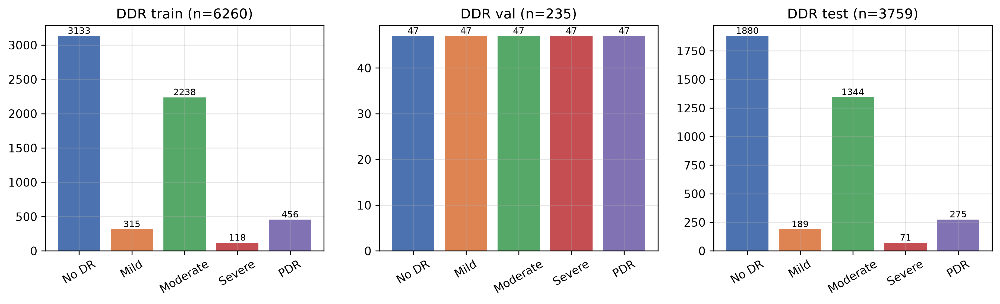

saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/train_grade_pie.png


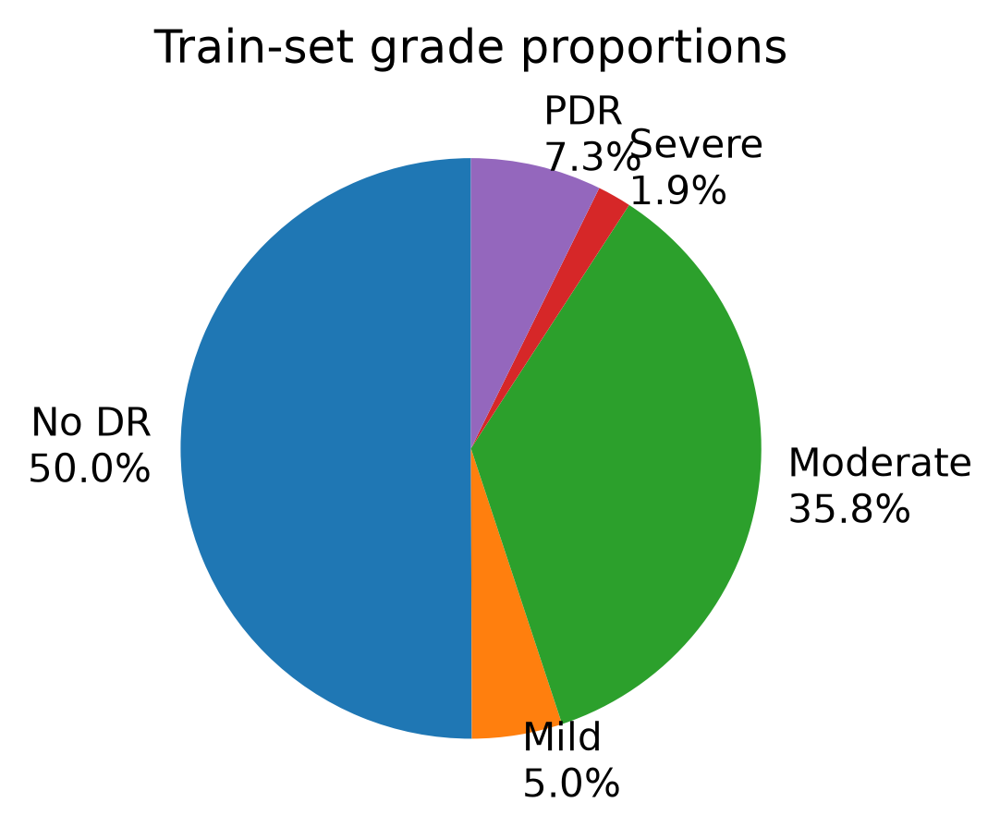

saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/prior_pool_composition.png


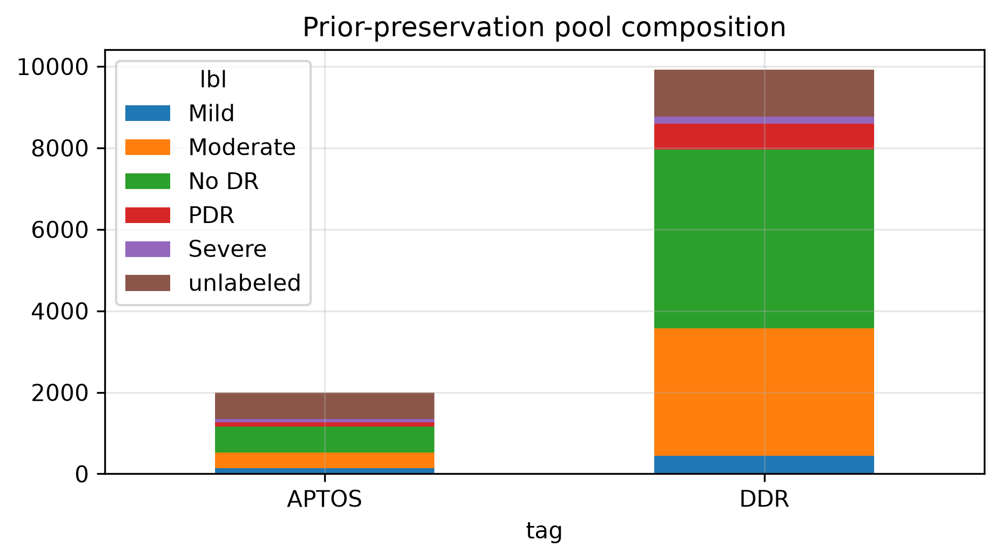

saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/samples_per_grade.png


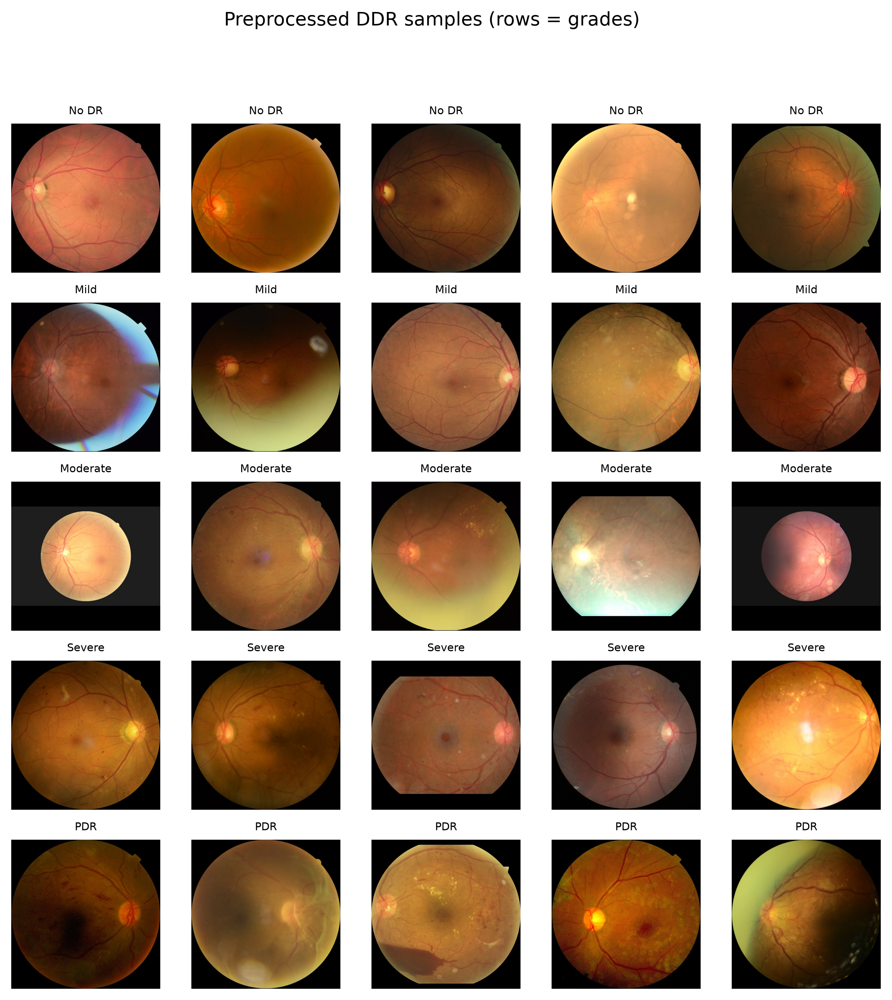

saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/color_stats_per_grade.png


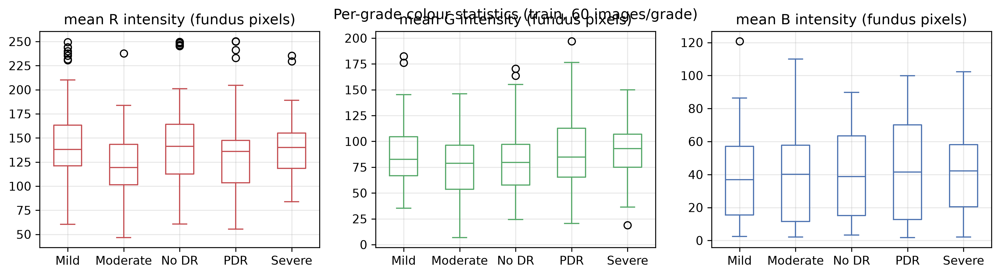

In [11]:
# =============================================================================
# 3. Dataset statistics and sample visualisations
# =============================================================================
stats = dataset_statistics(splits, prior_pool, FIG, raw_examples=raw_examples)

## 4. Official LANet checkpoints
(a) The six released LANet models form the **semantic scorer ensemble** (`score_j = mean_i softmax(g_i(x))[j]`).
(b) The LANet authors' models give the **LANet\*** row of Table 1 directly (no training).
If the Google-Drive download fails, the notebook falls back to our own LANet baseline as scorer (documented deviation).

In [12]:
# =============================================================================
# 4. Official LANet checkpoints: (a) semantic scorers, (b) quick reproduction check of 'LANet*'
# =============================================================================
train_items = list(zip(splits["train"].path, splits["train"].label))
val_items = list(zip(splits["val"].path, splits["val"].label))
test_items = list(zip(splits["test"].path, splits["test"].label))
real_labels = splits["train"].label.values

try:
    CKPT_ROOT = download_official_lanet_ckpts(WORK / "checkpoints_official" / "LANet_checkpoints", CFG["LANET_CKPT_GDRIVE_ID"])
except Exception as e:
    print("[warn] could not get official LANet checkpoints:", e); CKPT_ROOT = None

# (b) LANet* row: evaluate the LANet authors' released models on the DDR test set (no training needed)
if CKPT_ROOT is not None:
    for bb in CFG["CLF_BACKBONES"]:
        p = find_ckpt(CKPT_ROOT, LANET_AUTHORS[bb])
        out = RES / f"LANet-star__{bb}"
        if p is None or (out / "test_metrics.json").exists():
            continue
        out.mkdir(parents=True, exist_ok=True)
        atomic_torch_save({"net": load_lanet_checkpoint(bb, p).state_dict(), "epoch": -1}, out / "best.pth")
        evaluate_run(out, bb, test_items, {**CFG, "CLF_BATCH": CFG["CLF_BATCH_BY_BB"][bb]}, f"LANet-star_{bb}", FIG)


def clf_run_dir(config, bb, seed):
    safe = config.replace("+ ", "").replace(" ", "_").replace("/", "")
    return WORK / "classifiers" / f"{safe}__{bb}__seed{seed}"


# (a) scorer ensemble; fallback = our own 'LANet' baseline runs (trained here first if needed)
try:
    SCORER, SCORER_NAMES = build_scorer_ensemble(CFG, CKPT_ROOT)
except RuntimeError:
    print("Training our own LANet baseline first so it can act as the semantic scorer ...")
    bb = CFG["CLF_BACKBONES"][0]
    rd = clf_run_dir("LANet", bb, CFG["SEEDS"][0])
    train_classifier(rd, bb, train_items, real_labels, val_items, {**CFG, "CLF_BATCH": CFG["CLF_BATCH_BY_BB"][bb]},
                     use_sampler=False, budget=BUDGET, seed=CFG["SEEDS"][0])
    SCORER, SCORER_NAMES = build_scorer_ensemble(CFG, None, fallback_runs=[(bb, rd)])
save_json({"scorers": SCORER_NAMES}, WORK / "results" / "scorers_used.json")

# sanity check: scorer accuracy on our balanced validation set
_vp = SCORER.probs([Image.open(p) for p in splits["val"].path])
print("scorer ensemble on val:", fmt_metrics(compute_metrics(splits["val"].label.values, _vp.argmax(1))))

[warn] official scorer checkpoints not found -> using our own trained LANet runs as scorers: ()
Training our own LANet baseline first so it can act as the semantic scorer ...
[LANet__vgg__seed0] already finished - skipping training
[warn] official scorer checkpoints not found -> using our own trained LANet runs as scorers: [('vgg', PosixPath('/home/i269028/sara_genai/outputs/base_repro/classifiers/LANet__vgg__seed0'))]
semantic scorer ensemble: 1 models -> ['/home/i269028/sara_genai/outputs/base_repro/classifiers/LANet__vgg__seed0']
scorer ensemble on val: balanced_acc=73.62 | kappa=88.50 | acc=73.62 | macro_f1=72.50


## 5. Diffusion fine-tuning (basic DM and ECC DM, stages mild & severe)
Objective: $\mathcal{L}=\text{MSE}_{DDR}+\alpha\,\text{MSE}_{prior}+\beta\,\text{MSE}_{ECC}$ with $\alpha=0.1$,
$\beta=0$ for the first 500 steps then $0.001$ (ECC DM only). Per optimizer step the log shows the three losses; every
`SAMPLE_EVERY` steps fixed-seed samples are saved and their mean semantic score is the **validation** curve.
`state.pt` is written every `CKPT_EVERY` steps (exact resume), `best_lora/` (best validation score) and `final/`.

diffusion models to train: ['ecc']

===== ECC DM | stage 1 (mild DR) | 441 DDR instance images =====


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


[ecc_stage1] trainable LoRA params: 1.59 M
[ecc_stage1] RESUMED at step 250
[ecc_stage1] instance imgs=441 prior imgs=11914 | steps 250->600 | micro-batch 2x(1+1+1) | grad-accum 8 | ECC=on
  step   260/600 | loss 0.0677 (inst 0.0606 prior 0.0708 sync 0.0000) | 5.2s/step
  step   270/600 | loss 0.1101 (inst 0.1008 prior 0.0926 sync 0.0000) | 4.5s/step
  step   280/600 | loss 0.1276 (inst 0.1162 prior 0.1141 sync 0.0000) | 4.5s/step
  step   290/600 | loss 0.1267 (inst 0.1116 prior 0.1511 sync 0.0000) | 4.5s/step
  [ECC] step 300: 3 samples kept (>= 0.7)
saved figure -> /home/i269028/sara_genai/outputs/base_repro/diffusion/ecc_stage1/samples/step_00300.png


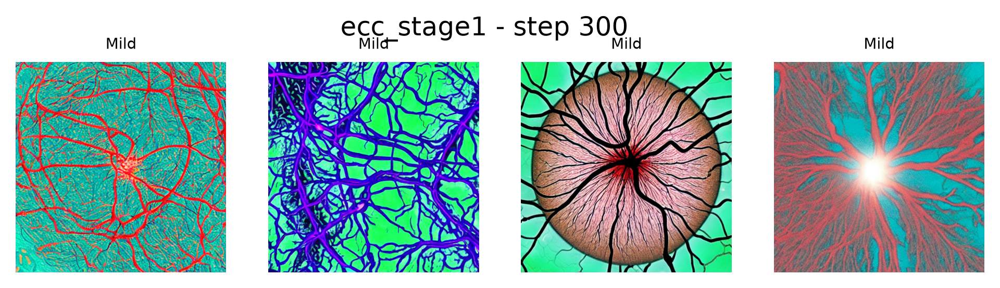

  step   300/600 | loss 0.0652 (inst 0.0576 prior 0.0763 sync 0.0000) | 18.9s/step | val semantic score 0.007
  step   310/600 | loss 0.1246 (inst 0.1159 prior 0.0858 sync 0.0884) | 7.1s/step
  step   320/600 | loss 0.0563 (inst 0.0413 prior 0.1483 sync 0.1742) | 6.4s/step
  step   330/600 | loss 0.0896 (inst 0.0813 prior 0.0829 sync 0.0450) | 6.4s/step
  step   340/600 | loss 0.0841 (inst 0.0762 prior 0.0772 sync 0.1325) | 6.4s/step
  [ECC] step 350: 5 samples kept (>= 0.7)
  step   350/600 | loss 0.1044 (inst 0.0971 prior 0.0715 sync 0.1455) | 18.7s/step
  step   360/600 | loss 0.0576 (inst 0.0493 prior 0.0817 sync 0.0956) | 6.6s/step
  step   370/600 | loss 0.1002 (inst 0.0914 prior 0.0863 sync 0.1301) | 6.6s/step
  step   380/600 | loss 0.0661 (inst 0.0593 prior 0.0673 sync 0.0829) | 6.6s/step
  step   390/600 | loss 0.0675 (inst 0.0535 prior 0.1390 sync 0.0937) | 6.6s/step
  [ECC] step 400: 6 samples kept (>= 0.7)
  step   400/600 | loss 0.1237 (inst 0.1158 prior 0.0775 sync 0.138

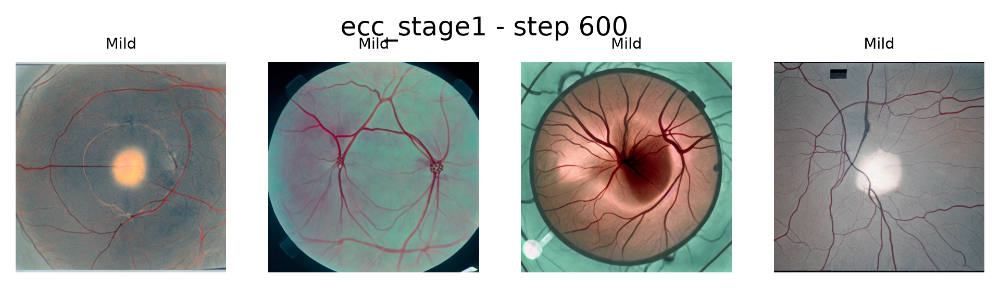

  step   600/600 | loss 0.1143 (inst 0.1085 prior 0.0565 sync 0.1330) | 20.1s/step | val semantic score 0.415
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/diffusion_history_ecc_stage1.png


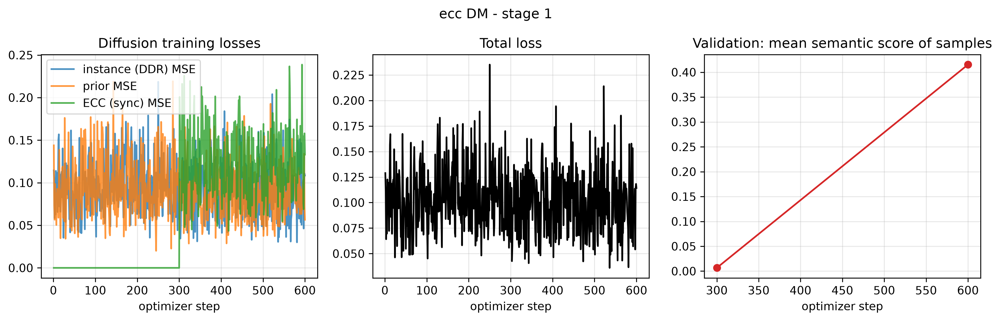

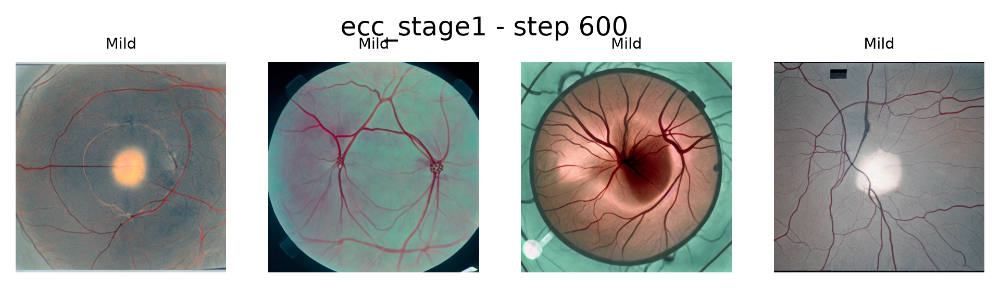


===== ECC DM | stage 3 (severe DR) | 165 DDR instance images =====


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


[ecc_stage3] trainable LoRA params: 1.59 M
[ecc_stage3] instance imgs=165 prior imgs=11914 | steps 0->600 | micro-batch 2x(1+1+1) | grad-accum 8 | ECC=on
  step     1/600 | loss 0.1183 (inst 0.1039 prior 0.1439 sync 0.0000) | 4.7s/step
  step    10/600 | loss 0.0614 (inst 0.0548 prior 0.0665 sync 0.0000) | 4.0s/step
  step    20/600 | loss 0.1315 (inst 0.1221 prior 0.0943 sync 0.0000) | 4.5s/step
  step    30/600 | loss 0.1284 (inst 0.1233 prior 0.0508 sync 0.0000) | 4.5s/step
  step    40/600 | loss 0.0409 (inst 0.0361 prior 0.0475 sync 0.0000) | 4.5s/step
  step    50/600 | loss 0.0580 (inst 0.0517 prior 0.0621 sync 0.0000) | 4.5s/step
  step    60/600 | loss 0.0528 (inst 0.0459 prior 0.0690 sync 0.0000) | 4.5s/step
  step    70/600 | loss 0.1498 (inst 0.1387 prior 0.1107 sync 0.0000) | 4.5s/step
  step    80/600 | loss 0.0960 (inst 0.0861 prior 0.0994 sync 0.0000) | 4.5s/step
  step    90/600 | loss 0.1538 (inst 0.1408 prior 0.1302 sync 0.0000) | 4.5s/step
  step   100/600 | loss 0.

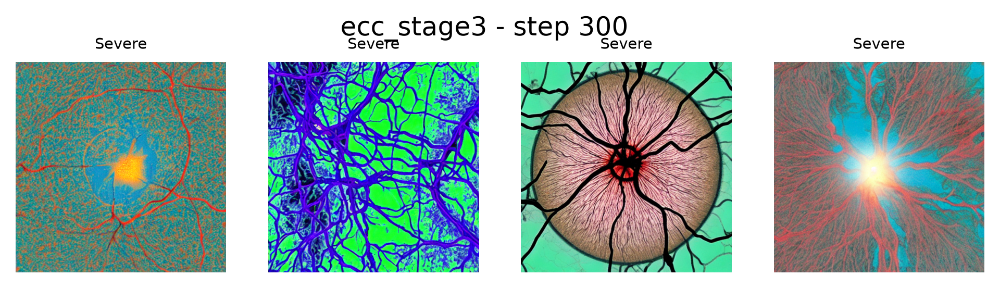

  step   300/600 | loss 0.0749 (inst 0.0683 prior 0.0660 sync 0.0000) | 17.6s/step | val semantic score 0.000
  step   310/600 | loss 0.1108 (inst 0.1029 prior 0.0796 sync 0.0000) | 4.5s/step
  step   320/600 | loss 0.0552 (inst 0.0405 prior 0.1466 sync 0.0000) | 4.5s/step
  step   330/600 | loss 0.0604 (inst 0.0534 prior 0.0706 sync 0.0000) | 4.5s/step
  step   340/600 | loss 0.0619 (inst 0.0535 prior 0.0845 sync 0.0000) | 4.5s/step
  [ECC] step 350: 2 samples kept (>= 0.7)
  step   350/600 | loss 0.1026 (inst 0.0963 prior 0.0635 sync 0.0000) | 16.8s/step
  step   360/600 | loss 0.0591 (inst 0.0493 prior 0.0968 sync 0.1312) | 7.0s/step
  step   370/600 | loss 0.1058 (inst 0.0969 prior 0.0873 sync 0.1341) | 7.0s/step
  step   380/600 | loss 0.0720 (inst 0.0648 prior 0.0711 sync 0.1436) | 7.0s/step
  step   390/600 | loss 0.0527 (inst 0.0398 prior 0.1279 sync 0.1124) | 7.0s/step
  [ECC] step 400: 4 samples kept (>= 0.7)
  step   400/600 | loss 0.1258 (inst 0.1165 prior 0.0912 sync 0.209

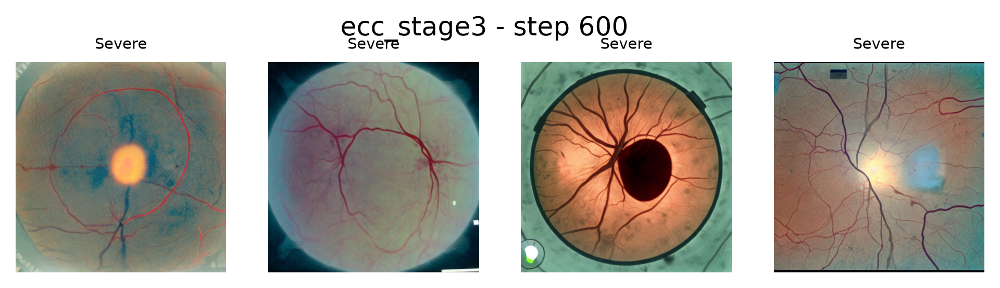

  step   600/600 | loss 0.1137 (inst 0.1084 prior 0.0529 sync 0.0000) | 17.7s/step | val semantic score 0.009
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/diffusion_history_ecc_stage3.png


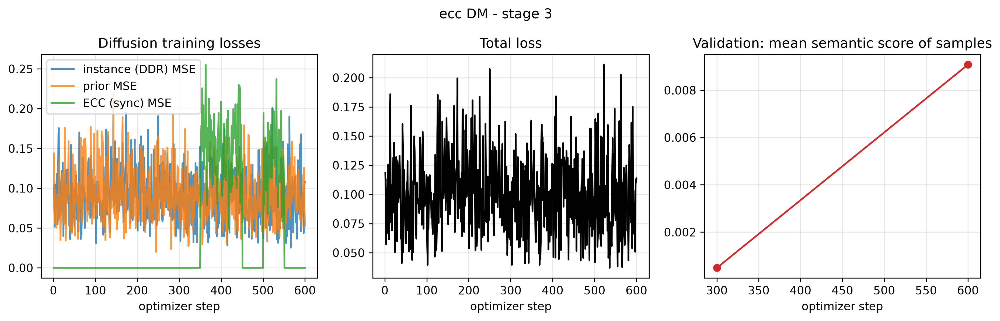

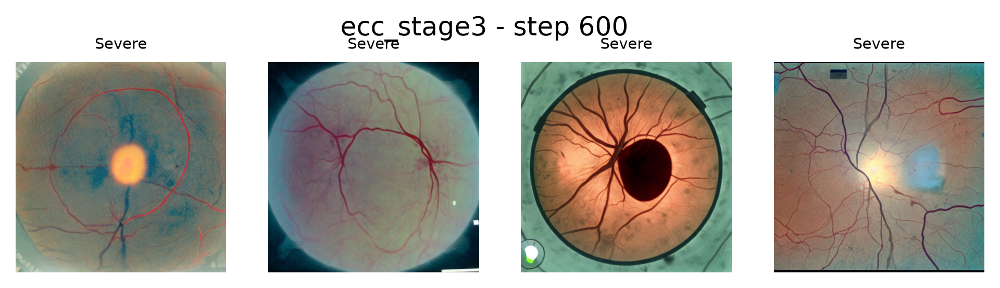

In [13]:
# =============================================================================
# 5. Diffusion model fine-tuning: one LoRA per DR stage (repo: `--stage`), basic DM and ECC DM
# =============================================================================
ddr_trainval = pd.concat([splits["train"], pd.read_csv(ddr_valid_path)]) if ddr_valid_path.exists() else splits["train"]
ddr_trainval = ddr_trainval[ddr_trainval.label != 5].drop_duplicates("name")
prior_items = list(zip(prior_pool.path, prior_pool.label, prior_pool.tag))


def stage_prompt(stage):
    return f"A color fundus image from DDR dataset in {STAGE_WORDS[stage]} stage."


# only train the diffusion models that the selected Table-1 rows (CFG["CONFIGS"]) actually need
NEEDED_DMS = [dm for dm in ["basic", "ecc"] if any(("ECC" in c) == (dm == "ecc") and "DM" in c for c in CFG["CONFIGS"])]
if CFG.get("RUN_AMOUNT_SWEEP") and "ecc" not in NEEDED_DMS:
    NEEDED_DMS.append("ecc")                     # Fig. 2a sweep uses ECC DM samples
print("diffusion models to train:", NEEDED_DMS)
DM_RUNS = {}
for dm in NEEDED_DMS:
    for stage in CFG["TARGET_STAGES"]:
        run_dir = WORK / "diffusion" / f"{dm}_stage{stage}"
        inst = [(p, int(l), "DDR") for p, l in zip(ddr_trainval.path, ddr_trainval.label) if int(l) == stage]
        ecc = None
        if dm == "ecc":
            E = CFG["ECC"]
            ecc = {"stage": stage, "prompt": stage_prompt(stage), "scorer": SCORER, "start_step": E["START_STEP"],
                   "interval": E["INTERVAL"], "n_runs": E["N_RUNS"], "per_run": E["PER_RUN"], "topk": E["TOPK"],
                   "min_score": E["MIN_SCORE"], "weight": E["WEIGHT"]}
        print(f"\n===== {dm.upper()} DM | stage {stage} ({STAGE_WORDS[stage]}) | {len(inst)} DDR instance images =====")
        try:
            hist = train_lora(run_dir, CFG, inst, prior_items, lambda it: labeltag2prompt(it[1], it[2], instance=True),
                              BUDGET, ecc=ecc, val_prompts=[(stage_prompt(stage), stage)], scorer=SCORER,
                              tag=f"{dm}_stage{stage}")
        except OutOfTime as e:
            print("\n>>> ", e); raise
        plot_diffusion_history(hist, f"{dm} DM - stage {stage}", FIG / f"diffusion_history_{dm}_stage{stage}.png")
        grids = sorted((run_dir / "samples").glob("*.png"))
        if grids: show_saved_figure(grids[-1])
        DM_RUNS[(dm, stage)] = run_dir / CFG["LORA_FOR_SAMPLING"]

## 6. Candidate generation and semantic scoring (resumable; every image and its 5-class score vector are saved)

In [14]:
# =============================================================================
# 6. Candidate generation + semantic scoring (resumable), for each DM and target stage
# =============================================================================
G = CFG["GEN"]


def in_window(df):
    return (df.score >= G["FILTER_LO"]) & (df.score <= G["FILTER_HI"])


def pool_mask(df):
    return df.repo_prefilter.astype(bool) if G["POOL"] == "repo_prefiltered" else pd.Series(True, index=df.index)


def enough(df):
    """Stop when both selections (w/o and w/ filter) can draw N_PER_CLASS images."""
    if not len(df):
        return False
    pm = pool_mask(df)
    return pm.sum() >= G["N_PER_CLASS"] and (pm & in_window(df)).sum() >= G["N_PER_CLASS"]


CANDIDATES = {}
for (dm, stage), lora_dir in DM_RUNS.items():
    out_dir = WORK / "synthetic" / f"{dm}_stage{stage}"
    csv = out_dir / "candidates.csv"
    if csv.exists():
        _df = pd.read_csv(csv)
        if enough(_df) or len(_df) >= G["MAX_CANDIDATES"]:
            CANDIDATES[(dm, stage)] = _df; print(f"{dm} stage {stage}: generation already complete ({len(_df)})"); continue
    pipe = make_inference_pipeline(CFG["SD_MODEL_ID"], lora_dir)
    try:
        df = generate_and_score(out_dir, pipe, stage_prompt(stage), stage, SCORER, BUDGET, n_max=G["MAX_CANDIDATES"],
                                stop_fn=enough, batch=G["BATCH"], steps=G["STEPS"], guidance=G["GUIDANCE"],
                                seed_base=(0 if dm == "basic" else 1) * 10 + stage)
    finally:
        del pipe; free_memory()
    CANDIDATES[(dm, stage)] = df
    print(f"{dm} stage {stage}: {len(df)} candidates | pool={pool_mask(df).sum()} | pool & [{G['FILTER_LO']},{G['FILTER_HI']}]="
          f"{(pool_mask(df) & in_window(df)).sum()} | mean score {df.score.mean():.3f}")

/home/i269028/sara_genai/sara_genai/lib/python3.12/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


... (2 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


[gen] 'A color fundus image from DDR dataset in severe DR stage.' -> /home/i269028/sara_genai/outputs/base_repro/synthetic/ecc_stage3 | have 0 | target <= 3000
  batch 0: total 8 | mean score 0.029 | in[0.7,0.9]: 0
  batch 10: total 88 | mean score 0.101 | in[0.7,0.9]: 2
  batch 20: total 168 | mean score 0.097 | in[0.7,0.9]: 3
  batch 30: total 248 | mean score 0.097 | in[0.7,0.9]: 6
  batch 40: total 328 | mean score 0.110 | in[0.7,0.9]: 11
  batch 50: total 408 | mean score 0.100 | in[0.7,0.9]: 11
  batch 60: total 488 | mean score 0.106 | in[0.7,0.9]: 14
  batch 70: total 568 | mean score 0.105 | in[0.7,0.9]: 17
  batch 80: total 648 | mean score 0.109 | in[0.7,0.9]: 20
  batch 90: total 728 | mean score 0.115 | in[0.7,0.9]: 22
  batch 100: total 808 | mean score 0.118 | in[0.7,0.9]: 24
  batch 110: total 888 | mean score 0.117 | in[0.7,0.9]: 26
  batch 120: total 968 | mean score 0.121 | in[0.7,0.9]: 30
  batch 130: total 1048 | mean score 0.118 | in[0.7,0.9]: 31
  batch 140: tota

## 7. Filtering & selection (w/o filter vs w/ filter, same number of images) + score histograms + Fig. 3-style inspection

[warn] ecc stage 1 w-filter: only 193 < 1000 available -> using all
[warn] ecc stage 3 w-filter: only 106 < 1000 available -> using all
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/semantic_score_histograms.png


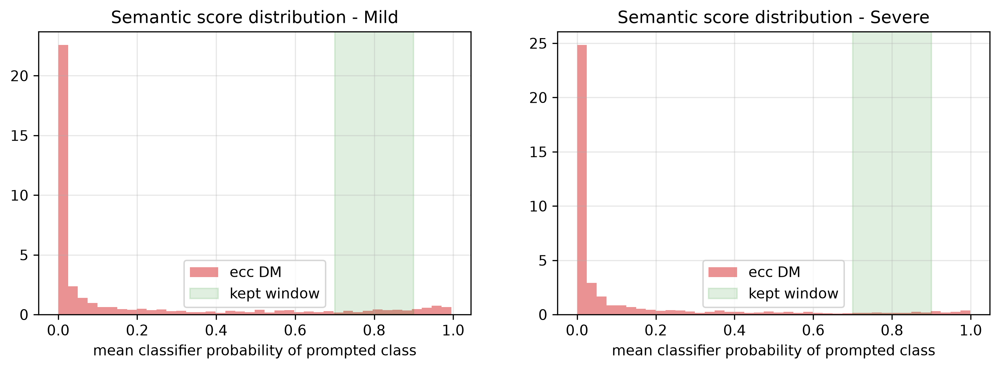

saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/fig3_semantic_inspection_stage1.png


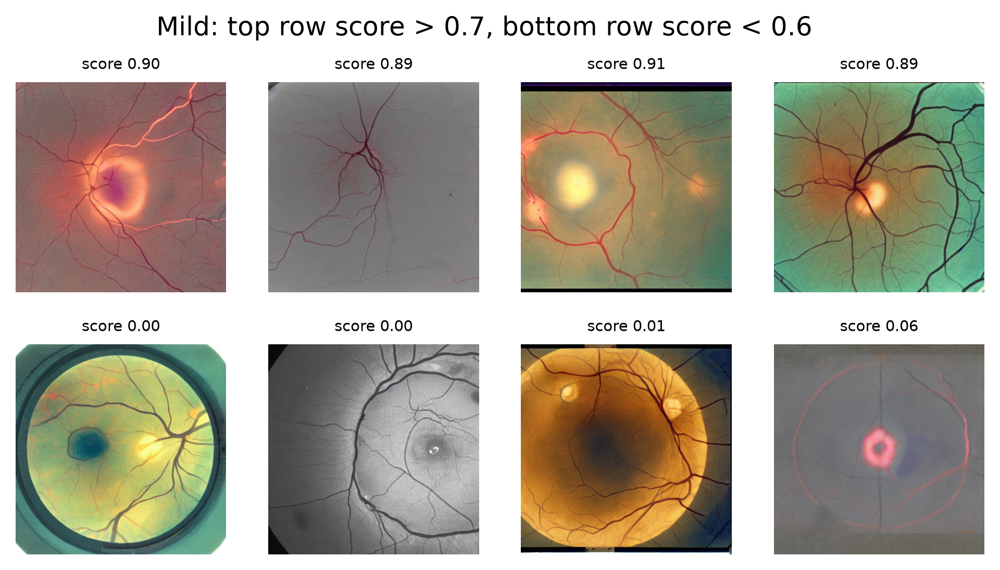

saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/fig3_semantic_inspection_stage3.png


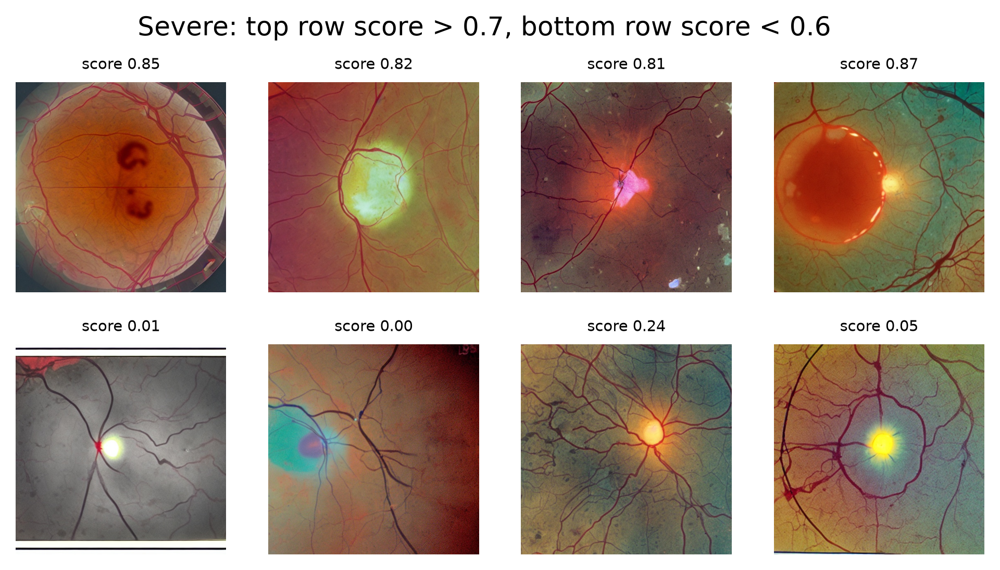

,dm,filter,stage,n,mean_score
0,ecc,wo,Mild,1000,0.191860
1,ecc,w,Mild,193,0.811087
2,ecc,wo,Severe,1000,0.134683
3,ecc,w,Severe,106,0.805465


In [15]:
# =============================================================================
# 7. Semantic-quality filtering and selection (Sec. 3.2) + score distributions + Fig.3-style inspection
#    w/o filter : random N from the pool            w/ filter : random N from pool with score in [0.7, 0.9]
#    (the total number of synthetic images is identical for both, as in Table 1)
# =============================================================================
SELECTIONS = {}
for (dm, stage), df in CANDIDATES.items():
    pool = df[pool_mask(df)]
    win = pool[in_window(pool)]
    n = G["N_PER_CLASS"]
    for flt, src in (("wo", pool), ("w", win)):
        if len(src) < n:
            print(f"[warn] {dm} stage {stage} {flt}-filter: only {len(src)} < {n} available -> using all")
        sel = src.sample(n=min(n, len(src)), random_state=42)
        SELECTIONS[(dm, flt, stage)] = sel
        sel.to_csv(WORK / "synthetic" / f"selection_{dm}_{flt}_stage{stage}.csv", index=False)

fig, axes = plt.subplots(1, len(CFG["TARGET_STAGES"]), figsize=(6 * len(CFG["TARGET_STAGES"]), 3.6))
axes = np.atleast_1d(axes)
for ax, stage in zip(axes, CFG["TARGET_STAGES"]):
    for dm, c in (("basic", "C0"), ("ecc", "C3")):
        if (dm, stage) in CANDIDATES:
            ax.hist(CANDIDATES[(dm, stage)].score, bins=40, alpha=.5, density=True, color=c, label=f"{dm} DM")
    ax.axvspan(G["FILTER_LO"], G["FILTER_HI"], color="green", alpha=.12, label="kept window")
    ax.set_title(f"Semantic score distribution - {GRADE_NAMES[stage]}"); ax.set_xlabel("mean classifier probability of prompted class"); ax.legend()
save_fig(fig, FIG / "semantic_score_histograms.png")

for stage in CFG["TARGET_STAGES"]:
    df = CANDIDATES.get(("ecc", stage), CANDIDATES.get(("basic", stage)))
    hi = df[df.score > 0.7].sample(n=min(4, (df.score > 0.7).sum()), random_state=0)
    lo = df[df.score < 0.6].sample(n=min(4, (df.score < 0.6).sum()), random_state=0)
    image_grid(list(hi.path) + list(lo.path), nrow=2,
               titles=[f"score {s:.2f}" for s in list(hi.score) + list(lo.score)],
               path=FIG / f"fig3_semantic_inspection_stage{stage}.png",
               suptitle=f"{GRADE_NAMES[stage]}: top row score > 0.7, bottom row score < 0.6")

summary = pd.DataFrame([{"dm": dm, "filter": flt, "stage": GRADE_NAMES[s], "n": len(v), "mean_score": v.score.mean()}
                        for (dm, flt, s), v in SELECTIONS.items()])
display(summary)

## 8. LANet classifiers for every Table-1 row
Faithful to `main_lanet.py`: ImageNet-pretrained backbone, SGD (lr 1e-3, momentum 0.9, wd 1e-5), poly lr decay,
adaptive multi-task loss, model selection on balanced-validation accuracy (epoch >= 10), weighted sampler for
oversampling (and, as in `train.sh`, for the synthetic configurations). Each epoch prints train loss/accuracy and
validation loss / accuracy / balanced accuracy / QWK / macro-F1; `last.pth` + `best.pth` + `history.csv` are saved.


######## LANet | vgg | seed 0 | +0 synthetic ########
[LANet__vgg__seed0] already finished - skipping training
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/curves_LANet__vgg__seed0.png


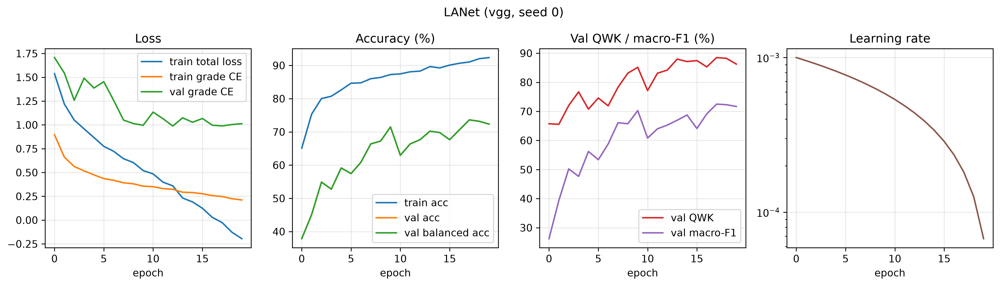

[LANet__vgg__seed0] TEST: balanced_acc=68.40 | kappa=83.62 | acc=81.03 | macro_f1=67.07
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/confusion_LANet__vgg__seed0.png


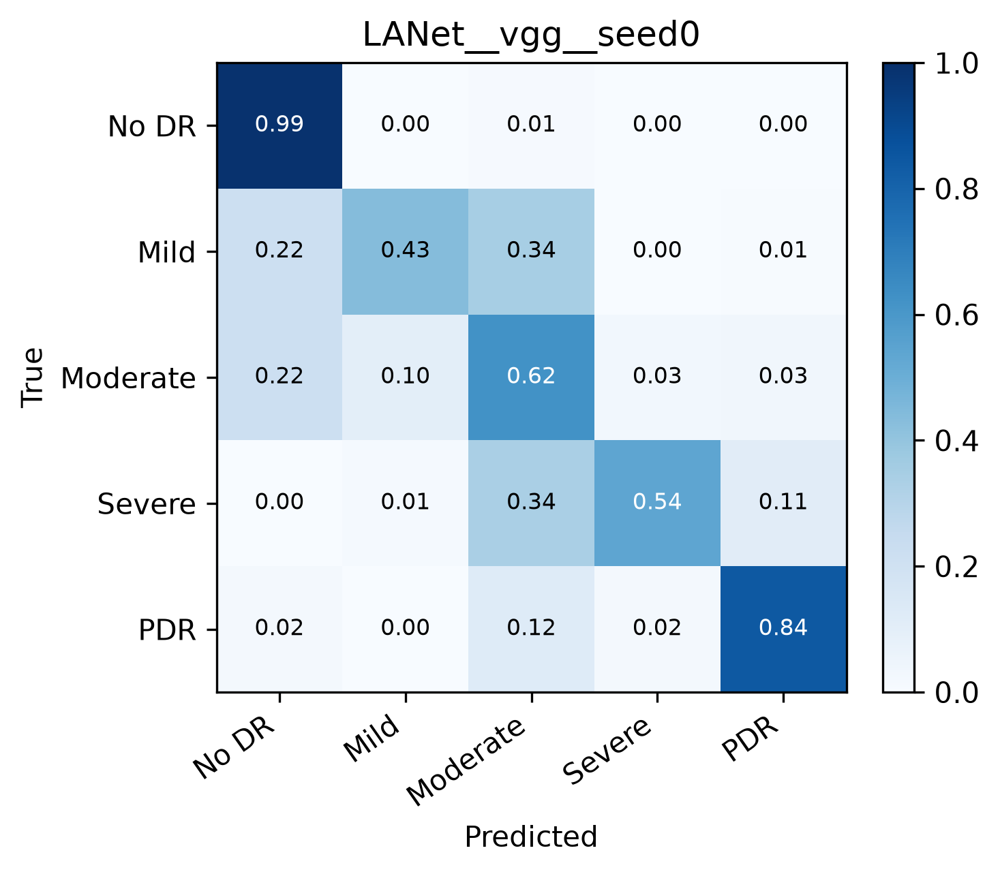


######## + oversampling | vgg | seed 0 | +0 synthetic ########
[oversampling__vgg__seed0] backbone=vgg | train items=6260 (real 6260) | sampler=True | epochs 0->20 | steps/epoch=241
  ep   1/20 | lr 1.00e-03 | train loss 1.6384 acc 47.62 | val loss 1.2791 acc 50.64 B.Acc 50.64 QWK 80.30 F1 49.41 | 2.4 min
  ep   2/20 | lr 9.55e-04 | train loss 1.1536 acc 64.28 | val loss 1.1162 acc 55.32 B.Acc 55.32 QWK 80.60 F1 49.50 | 2.3 min
  ep   3/20 | lr 9.10e-04 | train loss 0.9815 acc 70.78 | val loss 0.9265 acc 65.11 B.Acc 65.11 QWK 80.55 F1 65.10 | 2.3 min
  ep   4/20 | lr 8.64e-04 | train loss 0.8192 acc 75.77 | val loss 0.9376 acc 64.26 B.Acc 64.26 QWK 84.89 F1 64.10 | 2.3 min
  ep   5/20 | lr 8.18e-04 | train loss 0.6573 acc 79.50 | val loss 0.8703 acc 68.94 B.Acc 68.94 QWK 81.41 F1 68.57 | 2.3 min
  ep   6/20 | lr 7.72e-04 | train loss 0.5520 acc 81.58 | val loss 0.9811 acc 67.23 B.Acc 67.23 QWK 85.18 F1 66.82 | 2.3 min
  ep   7/20 | lr 7.25e-04 | train loss 0.5091 acc 81.98 | val loss 

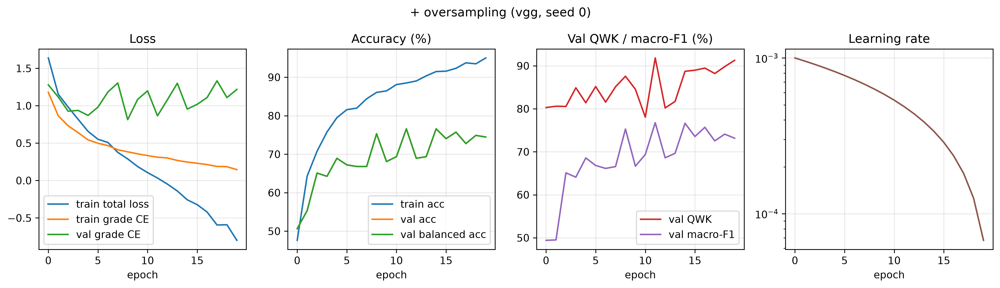

[oversampling__vgg__seed0] TEST: balanced_acc=71.43 | kappa=79.84 | acc=72.71 | macro_f1=60.87
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/confusion_oversampling__vgg__seed0.png


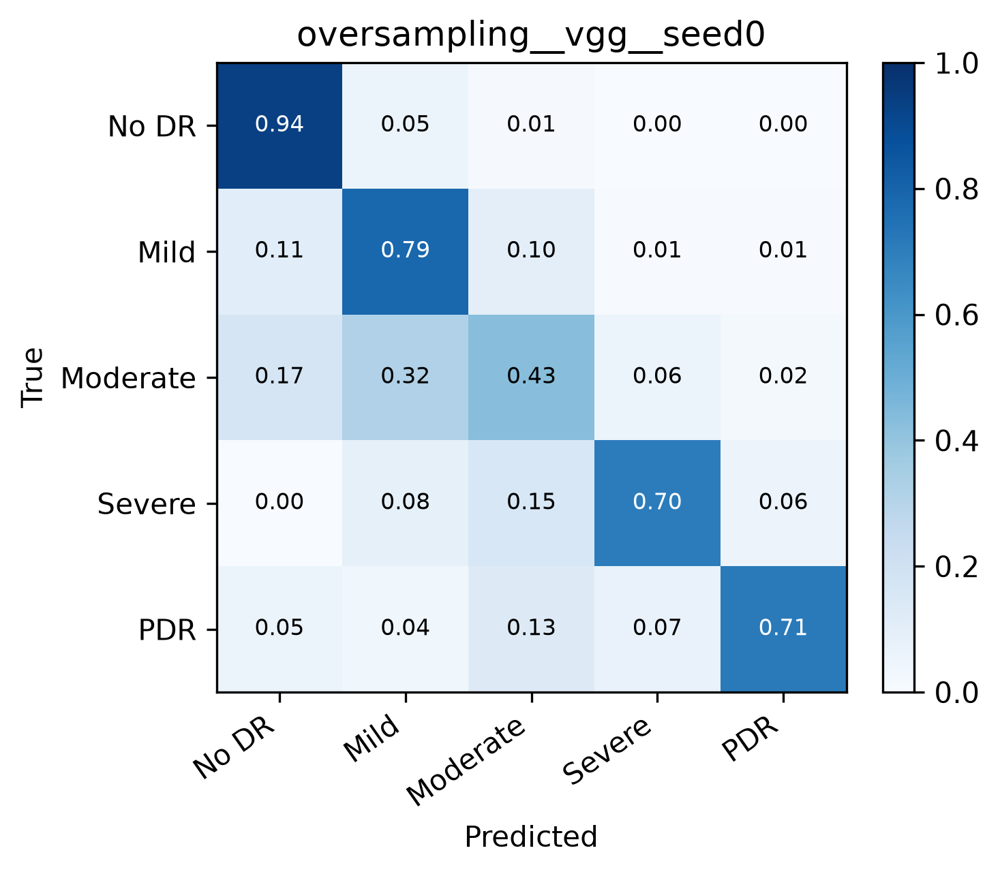


######## + ECC DM w/o filter | vgg | seed 0 | +2000 synthetic ########
[ECC_DM_wo_filter__vgg__seed0] backbone=vgg | train items=8260 (real 6260) | sampler=True | epochs 0->20 | steps/epoch=241
  ep   1/20 | lr 1.00e-03 | train loss 0.7572 acc 73.39 | val loss 1.2645 acc 47.66 B.Acc 47.66 QWK 67.17 F1 42.37 | 2.3 min
  ep   2/20 | lr 9.55e-04 | train loss -0.2852 acc 82.80 | val loss 1.2562 acc 46.81 B.Acc 46.81 QWK 70.31 F1 39.78 | 2.3 min
  ep   3/20 | lr 9.10e-04 | train loss -0.4485 acc 83.66 | val loss 1.1872 acc 48.51 B.Acc 48.51 QWK 72.95 F1 46.65 | 2.3 min
  ep   4/20 | lr 8.64e-04 | train loss -0.6917 acc 86.41 | val loss 1.0155 acc 59.15 B.Acc 59.15 QWK 75.56 F1 56.55 | 2.3 min
  ep   5/20 | lr 8.18e-04 | train loss -0.8010 acc 87.92 | val loss 1.0784 acc 58.72 B.Acc 58.72 QWK 74.34 F1 59.25 | 2.3 min
  ep   6/20 | lr 7.72e-04 | train loss -1.0142 acc 89.07 | val loss 0.9693 acc 62.13 B.Acc 62.13 QWK 80.60 F1 60.70 | 2.3 min
  ep   7/20 | lr 7.25e-04 | train loss -1.0067 acc

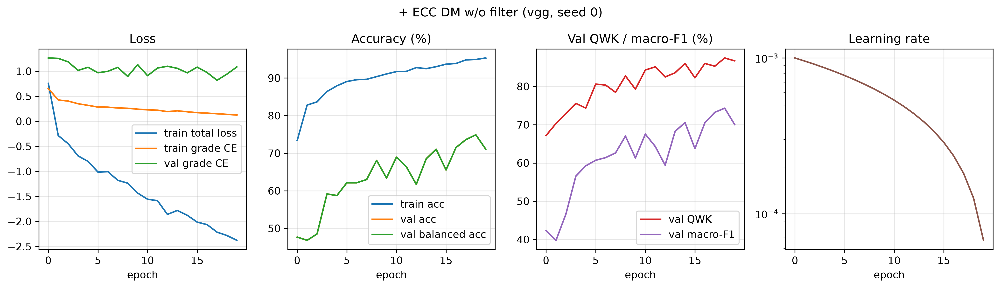

[ECC_DM_wo_filter__vgg__seed0] TEST: balanced_acc=70.88 | kappa=80.50 | acc=74.86 | macro_f1=60.97
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/confusion_ECC_DM_wo_filter__vgg__seed0.png


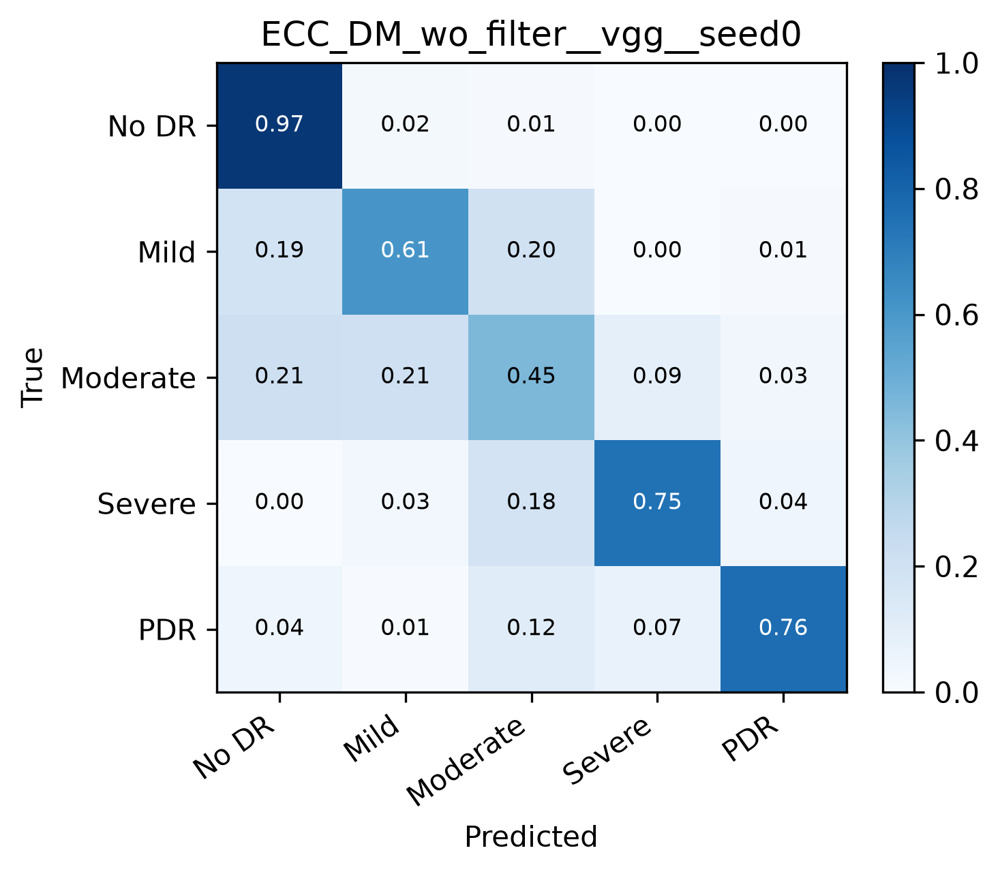


######## + ECC DM w/ filter | vgg | seed 0 | +299 synthetic ########
[ECC_DM_w_filter__vgg__seed0] backbone=vgg | train items=6559 (real 6260) | sampler=True | epochs 0->20 | steps/epoch=241
  ep   1/20 | lr 1.00e-03 | train loss 1.3718 acc 57.86 | val loss 1.2148 acc 49.79 B.Acc 49.79 QWK 75.84 F1 48.85 | 2.3 min
  ep   2/20 | lr 9.55e-04 | train loss 0.7631 acc 71.21 | val loss 1.0375 acc 64.68 B.Acc 64.68 QWK 82.50 F1 64.01 | 2.3 min
  ep   3/20 | lr 9.10e-04 | train loss 0.6056 acc 76.69 | val loss 1.0397 acc 60.43 B.Acc 60.43 QWK 75.93 F1 57.87 | 2.3 min
  ep   4/20 | lr 8.64e-04 | train loss 0.4472 acc 79.33 | val loss 1.0055 acc 63.83 B.Acc 63.83 QWK 77.53 F1 62.45 | 2.3 min
  ep   5/20 | lr 8.18e-04 | train loss 0.3575 acc 81.68 | val loss 1.0661 acc 61.70 B.Acc 61.70 QWK 79.17 F1 58.45 | 2.3 min
  ep   6/20 | lr 7.72e-04 | train loss 0.2192 acc 83.53 | val loss 1.0722 acc 66.81 B.Acc 66.81 QWK 81.92 F1 66.52 | 2.3 min
  ep   7/20 | lr 7.25e-04 | train loss 0.1754 acc 84.60 | 

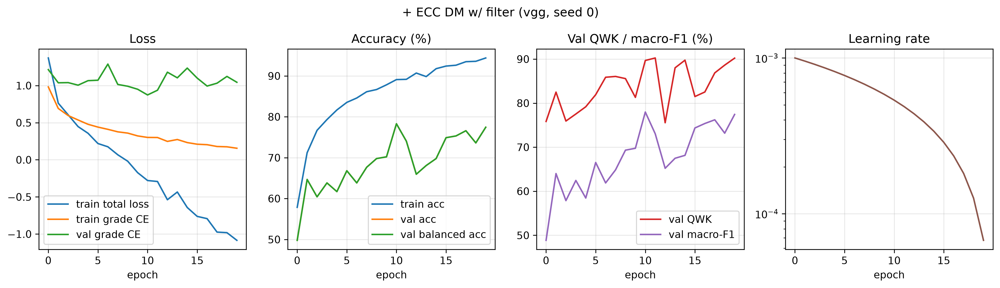

[ECC_DM_w_filter__vgg__seed0] TEST: balanced_acc=69.86 | kappa=80.14 | acc=76.16 | macro_f1=64.53
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/confusion_ECC_DM_w_filter__vgg__seed0.png


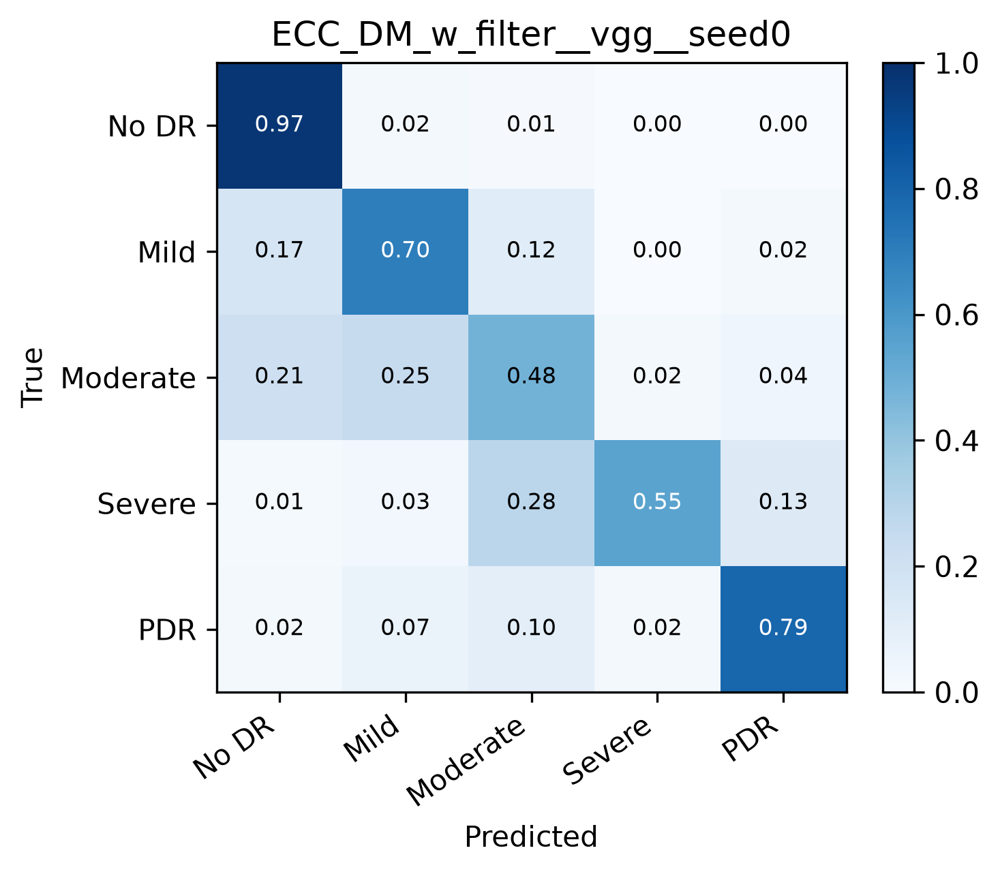

In [16]:
# =============================================================================
# 8. LANet training for every Table-1 row (per-epoch train/val logs, best/last checkpoints, auto-resume)
# =============================================================================
def synth_items_for(config):
    """Map a Table-1 row to its synthetic training images (mild + severe)."""
    if "DM" not in config:
        return []
    dm = "ecc" if "ECC" in config else "basic"
    flt = "w" if "w/ filter" in config else "wo"
    items = []
    for stage in CFG["TARGET_STAGES"]:
        sel = SELECTIONS.get((dm, flt, stage))
        if sel is None:
            f = WORK / "synthetic" / f"selection_{dm}_{flt}_stage{stage}.csv"
            sel = pd.read_csv(f) if f.exists() else None
        if sel is not None:
            items += list(zip(sel.path, sel.label.astype(int)))
    return items


RUN_TABLE = []
for bb in CFG["CLF_BACKBONES"]:
    rcfg = {**CFG, "CLF_BATCH": CFG["CLF_BATCH_BY_BB"][bb]}
    for config in CFG["CONFIGS"]:
        for seed in CFG["SEEDS"]:
            synth = synth_items_for(config)
            if "DM" in config and not synth:
                print(f"[skip] {config}: no synthetic selection found (run Sections 5-7 first)"); continue
            use_sampler = (config == "+ oversampling") or ("DM" in config and CFG["USE_SAMPLER_WITH_SYNTH"])
            rd = clf_run_dir(config, bb, seed)
            print(f"\n######## {config} | {bb} | seed {seed} | +{len(synth)} synthetic ########")
            hist = train_classifier(rd, bb, train_items + synth, real_labels, val_items, rcfg,
                                    use_sampler=use_sampler, budget=BUDGET, seed=seed)
            plot_classifier_history(hist, f"{config} ({bb}, seed {seed})", FIG / f"curves_{rd.name}.png")
            m = evaluate_run(rd, bb, test_items, rcfg, rd.name, FIG)
            RUN_TABLE.append({"config": config, "backbone": bb, "seed": seed, "n_synth": len(synth), **m})
            save_json(RUN_TABLE, RES / "all_runs.json")

## 9. Reproduced Table 1 vs the paper, comparison plots, released-checkpoint check

balanced_acc      kappa        acc     macro_f1  \
                                     mean std   mean std   mean std     mean   
backbone config                                                                
vgg      + ECC DM w/ filter         69.86 NaN  80.14 NaN  76.16 NaN    64.53   
         + ECC DM w/o filter        70.88 NaN  80.50 NaN  74.86 NaN    60.97   
         + oversampling             71.43 NaN  79.84 NaN  72.71 NaN    60.87   
         LANet                      68.40 NaN  83.62 NaN  81.03 NaN    67.07   

                                  
                             std  
backbone config                   
vgg      + ECC DM w/ filter  NaN  
         + ECC DM w/o filter NaN  
         + oversampling      NaN  
         LANet               NaN

,backbone,config,ours_B.Acc,paper_B.Acc,ours_Kappa,paper_Kappa,ours_Acc,paper_Acc,ours_macroF1,recall_No DR,recall_Mild,recall_Moderate,recall_Severe,recall_PDR
0,vgg,LANet,68.40,66.84,83.62,85.06,81.03,83.67,67.07,98.88,43.39,62.20,53.52,84.00
1,vgg,+ oversampling,71.43,68.78,79.84,82.47,72.71,79.06,60.87,93.67,78.84,42.93,70.42,71.27
2,vgg,+ ECC DM w/o filter,70.88,74.20,80.50,81.38,74.86,75.02,60.97,97.07,60.85,45.46,74.65,76.36
3,vgg,+ ECC DM w/ filter,69.86,73.82,80.14,82.58,76.16,76.80,64.53,97.34,69.84,47.92,54.93,79.27


saved -> /home/i269028/sara_genai/outputs/base_repro/results/table1_reproduction.csv and .tex
saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/reproduction_vs_paper_vgg.png


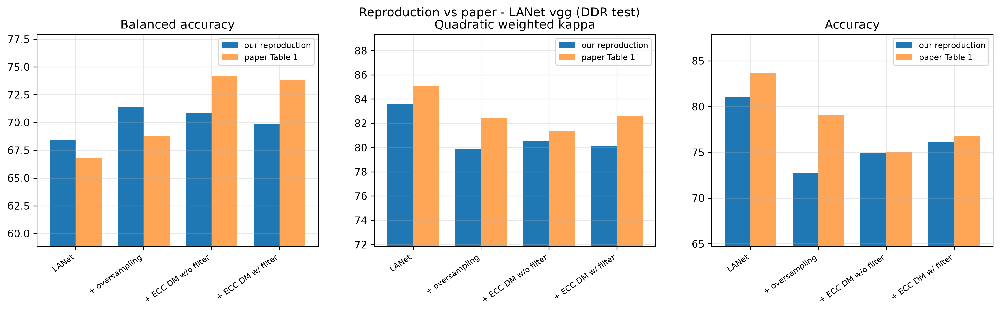

saved figure -> /home/i269028/sara_genai/outputs/base_repro/figures/per_grade_recall_vgg.png


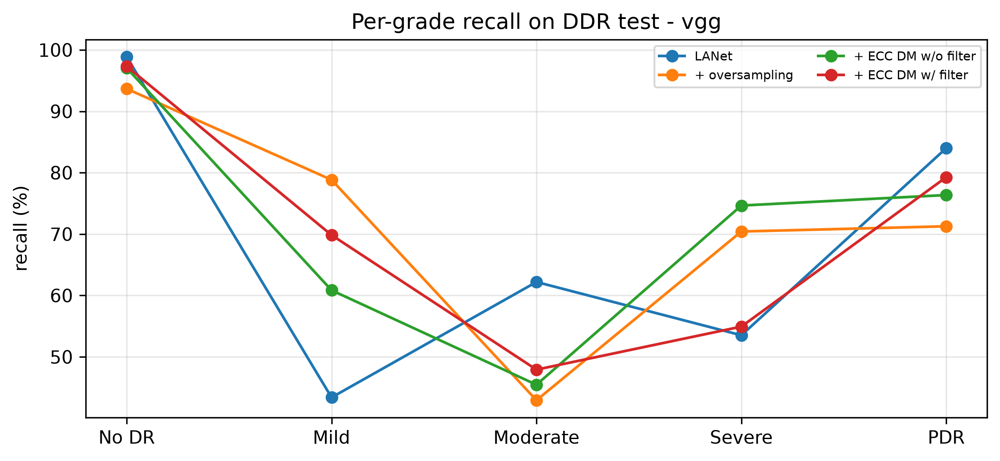

In [17]:
# =============================================================================
# 9. Reproduced Table 1 vs the paper, comparison plots, released-checkpoint check
# =============================================================================
rows = []
for r in load_json(RES / "all_runs.json", []):
    rows.append(r)
for p in RES.glob("LANet-star__*/test_metrics.json"):
    m = load_json(p); rows.append({"config": "LANet*", "backbone": m["backbone"], "seed": -1, "n_synth": 0, **m})
res_df = pd.DataFrame(rows)

if len(res_df):
    agg = (res_df.groupby(["backbone", "config"])[["balanced_acc", "kappa", "acc", "macro_f1"]]
           .agg(["mean", "std"]) * 100).round(2)
    display(agg)
    table = []
    order = ["LANet*"] + CFG["CONFIGS"]
    for bb in res_df.backbone.unique():
        for c in order:
            d = res_df[(res_df.backbone == bb) & (res_df.config == c)]
            if not len(d): continue
            pb = PAPER_TABLE1.get(bb, {}).get(c, (np.nan,) * 3)
            pcr = np.nanmean(np.vstack(d.per_class_recall.values), 0) * 100
            table.append({"backbone": bb, "config": c, "ours_B.Acc": 100 * d.balanced_acc.mean(), "paper_B.Acc": pb[0],
                          "ours_Kappa": 100 * d.kappa.mean(), "paper_Kappa": pb[1], "ours_Acc": 100 * d.acc.mean(),
                          "paper_Acc": pb[2], "ours_macroF1": 100 * d.macro_f1.mean(),
                          **{f"recall_{GRADE_NAMES[i]}": pcr[i] for i in range(5)}})
    table = pd.DataFrame(table).round(2)
    display(table)
    table.to_csv(RES / "table1_reproduction.csv", index=False)
    with open(RES / "table1_reproduction.tex", "w") as f:
        f.write(table.to_latex(index=False, float_format="%.2f"))
    print("saved ->", RES / "table1_reproduction.csv", "and .tex")

    for bb in table.backbone.unique():
        t = table[table.backbone == bb]
        x = np.arange(len(t)); w = 0.38
        fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
        for ax, (o, p, name) in zip(axes, [("ours_B.Acc", "paper_B.Acc", "Balanced accuracy"),
                                           ("ours_Kappa", "paper_Kappa", "Quadratic weighted kappa"),
                                           ("ours_Acc", "paper_Acc", "Accuracy")]):
            ax.bar(x - w / 2, t[o], w, label="our reproduction"); ax.bar(x + w / 2, t[p], w, label="paper Table 1", alpha=.7)
            ax.set_xticks(x); ax.set_xticklabels(t.config, rotation=35, ha="right", fontsize=8); ax.set_title(name)
            lo = np.nanmin(np.r_[t[o].values, t[p].values]); ax.set_ylim(max(0, lo - 8), None); ax.legend(fontsize=8)
        fig.suptitle(f"Reproduction vs paper - LANet {bb} (DDR test)")
        save_fig(fig, FIG / f"reproduction_vs_paper_{bb}.png")

        fig, ax = plt.subplots(figsize=(9, 3.8))
        for i, r in t.iterrows():
            ax.plot(GRADE_NAMES, [r[f"recall_{g}"] for g in GRADE_NAMES], "o-", label=r.config)
        ax.set_ylabel("recall (%)"); ax.set_title(f"Per-grade recall on DDR test - {bb}"); ax.legend(fontsize=7, ncol=2)
        save_fig(fig, FIG / f"per_grade_recall_{bb}.png")

# ---- optional: the authors' released VGG models trained with ECC synthetic data (5 folds) ----
if CFG["RUN_RELEASED_CKPT_CHECK"]:
    try:
        rel_dir = WORK / "checkpoints_official" / "released_ecc_vgg"
        if not any(rel_dir.rglob("*.pkl")):
            download_official_lanet_ckpts(rel_dir, CFG["RELEASED_ECC_VGG_GDRIVE_ID"])
        rel = []
        for p in sorted(rel_dir.rglob("*.pkl")):
            out = RES / f"released_ecc_vgg__{p.parent.name}_{p.stem}"
            out.mkdir(parents=True, exist_ok=True)
            if not (out / "best.pth").exists():
                atomic_torch_save({"net": load_lanet_checkpoint("vgg", p).state_dict(), "epoch": -1}, out / "best.pth")
            rel.append(evaluate_run(out, "vgg", test_items, {**CFG, "CLF_BATCH": 26}, out.name, FIG))
        if rel:
            print("Released ECC-VGG checkpoints, mean over files: " +
                  fmt_metrics({k: np.mean([r[k] for r in rel]) for k in ("balanced_acc", "kappa", "acc", "macro_f1")}),
                  "| paper (+ECC DM w/o filter, VGG): B.Acc 74.20 Kappa 81.38 Acc 75.02")
    except Exception as e:
        print("[warn] released checkpoint check skipped:", e)

## 10-12. Optional amount sweep (Fig. 2a), FID/KID of synthetic data, export

In [18]:
# =============================================================================
# 10. (optional) Performance vs. amount of synthetic data (paper Fig. 2a) - ECC DM w/o filter
# =============================================================================
if CFG["RUN_AMOUNT_SWEEP"]:
    bb = CFG["CLF_BACKBONES"][0]; rcfg = {**CFG, "CLF_BATCH": CFG["CLF_BATCH_BY_BB"][bb]}
    sweep = []
    for amount in CFG["AMOUNT_SWEEP"]:
        items = []
        for stage in CFG["TARGET_STAGES"]:
            sel = SELECTIONS[("ecc", "wo", stage)]
            items += list(zip(sel.path[:amount], sel.label[:amount].astype(int)))
        rd = WORK / "classifiers" / f"sweep_{amount}__{bb}"
        hist = train_classifier(rd, bb, train_items + items, real_labels, val_items, rcfg,
                                use_sampler=CFG["USE_SAMPLER_WITH_SYNTH"], budget=BUDGET)
        m = evaluate_run(rd, bb, test_items, rcfg, rd.name, FIG)
        sweep.append({"synthetic_total": 2 * amount, **m})
    sw = pd.DataFrame(sweep); save_json(sweep, RES / "amount_sweep.json")
    fig, ax = plt.subplots(figsize=(6, 3.8))
    for k, lab in (("balanced_acc", "B.Acc"), ("acc", "Acc"), ("kappa", "Kappa")):
        ax.plot(sw.synthetic_total, 100 * sw[k], "o-", label=lab)
    ax.set_xlabel("# synthetic images (mild + severe)"); ax.set_ylabel("%"); ax.legend(); ax.set_title("Performance vs synthetic amount")
    save_fig(fig, FIG / "fig2a_amount_sweep.png")
else:
    print("Amount sweep disabled (CFG['RUN_AMOUNT_SWEEP']=False).")

# =============================================================================
# 11. Synthetic-image quality (FID / KID per stage) - reused by notebook 2 for the comparison table
# =============================================================================
gen_rows = []
for (dm, flt, stage), sel in SELECTIONS.items():
    out = RES / f"genmetrics_{dm}_{flt}_stage{stage}.json"
    if out.exists():
        gen_rows.append(load_json(out)); continue
    real = list(splits["train"][splits["train"].label == stage].path)
    fake = list(sel.path)
    try:
        m = fid_kid(real, fake)
    except Exception as e:
        print("[warn] FID/KID failed:", e); continue
    m.update({"method": f"base_{dm}_{flt}", "stage": stage}); save_json(m, out); gen_rows.append(m)
if gen_rows:
    gm = pd.DataFrame(gen_rows); display(gm); gm.to_csv(RES / "generative_metrics_base.csv", index=False)

# =============================================================================
# 12. Export: everything notebook 2 needs for the comparison lives in base_repro/results and base_repro/splits
# =============================================================================
print("Output size so far: %.2f GB" % disk_usage_gb(WORK))
print("Done. Save a version (Save & Run All / Quick Save) so the outputs persist, then attach them to notebook 2.")

Amount sweep disabled (CFG['RUN_AMOUNT_SWEEP']=False).


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /home/i269028/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:08<00:00, 11.1MB/s]


,fid,kid_mean,kid_std,n_real,n_fake,method,stage
0,178.510742,0.165905,0.008062,315,1000,base_ecc_wo,1
1,195.735321,0.192835,0.008243,315,193,base_ecc_w,1
2,170.897964,0.121758,0.007005,118,1000,base_ecc_wo,3
3,185.274048,0.140231,0.002521,118,106,base_ecc_w,3


Output size so far: 4.10 GB
Done. Save a version (Save & Run All / Quick Save) so the outputs persist, then attach them to notebook 2.
